# 05 - Deep-Learning Architecture Comparison (Member 3)

> **Status: this notebook has NOT been executed.** It contains no results, metrics or trained models. Every table, figure, checkpoint and report it creates is produced only when *you* run it.

## 1. Research objective

**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN.*

The long-term goal is **robustness to inference-time telemetry manipulation** (another team member's work). Before that stage, we need a small set of well-understood neural architectures that detect attacks on clean data, trained under identical conditions, so that the most promising ones can be carried forward.
This notebook therefore **compares six architectures x three modalities** for binary intrusion detection (`is_attack`: 0 = Benign, **1 = Attack = positive class**) and exports checkpoints that contain everything needed to run manipulation experiments later.

Clean-data accuracy is only one stage of the research. A high clean-data score **does not** demonstrate robustness, and it does not demonstrate generalisation to unseen 5G deployments (see section 20).

## 2. Experimental design

| # | Architecture | Input representation | Role |
|---|---|---|---|
| 1 | **MLP** | feature vector `(B, F)` | reference |
| 2 | **1D CNN** | vector as a 1-channel signal `(B, 1, F)` | *assumes* adjacent columns are neighbours - not a temporal model |
| 3 | **LSTM** | features as a sequence of `F` positions (value + learnable feature-ID embedding) | exploratory; positions are **not** time steps |
| 4 | **GRU** | identical representation, head and hyper-parameters as the LSTM | exploratory; fair LSTM/GRU comparison |
| 5 | **Residual MLP** | feature vector | compared with the plain MLP |
| 6 | **FT-Transformer** | one learnable token per numerical feature + `[CLS]` | tabular-specific attention model |

**Modalities:** Network (29 approved features), Radio (32 approved Profile A features), Multimodal (61 = 29 + 32).
**Experiments:** 6 architectures x 3 modalities = **18 experiments**, each with **5 independent seeds** = 90 training runs.

**Fixed rules (identical for all runs):**
* The exact existing split from `Results/split_manifest.csv` (train / validation / test, scenario-grouped). Nothing is re-split.
* Imputation, standardisation and class weights are fitted on **training rows only**.
* AdamW, weighted BCE-with-logits, early stopping on **validation loss** (patience 12, max 100 epochs), best-validation weights restored. All hyper-parameters live in one configuration cell (section 4).
* Fixed threshold **0.5**. **The test partition is locked** (access raises an error) until all training is finished and a hash of every decision and weight has been stored. Test data is never used for early stopping, tuning, architecture selection or thresholds.
* Architectures are **ranked using validation metrics only**; test metrics are reported separately and never used to declare a winner.

**Not in scope here:** telemetry manipulation, adversarial attacks, trust scoring, sensor-reliability mechanisms, defenses.

## 3. Imports and environment setup
The notebook **never installs or upgrades packages**. If something is missing it stops and prints the installation command. Required: `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `torch`.

In [2]:
!pip install numpy pandas scipy scikit-learn matplotlib torch

Defaulting to user installation because normal site-packages is not writeable


In [9]:
# ---- 3. Imports and environment ----------------------------------------------------------------------------------------------
import os, sys, json, time, random, hashlib, platform, importlib, tempfile, re
from pathlib import Path
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")          # deterministic CUDA matmuls (ignored on CPU)
sys.dont_write_bytecode = True

REQUIRED = {"numpy": "1.22", "pandas": "1.5", "scipy": "1.8", "sklearn": "1.2", "matplotlib": "3.5", "torch": "2.0"}
INSTALL_HINT = {"numpy": "pip install numpy", "pandas": "pip install pandas", "scipy": "pip install scipy", "sklearn": "pip install scikit-learn",
                "matplotlib": "pip install matplotlib",
                "torch": "pip install torch    (CPU-only: pip install torch --index-url https://download.pytorch.org/whl/cpu)"}
_missing, _old, FOUND = [], [], {}
for _mod, _need in REQUIRED.items():
    try:
        FOUND[_mod] = importlib.import_module(_mod).__version__
        if tuple(int(x) for x in FOUND[_mod].split("+")[0].split(".")[:2]) < tuple(int(x) for x in _need.split(".")[:2]): _old.append(_mod)
    except ImportError:
        _missing.append(_mod)
if _missing or _old:
    _msg = ["Required packages are missing or too old; this notebook does NOT install anything."]
    _msg += [f"  missing: {m}   ->   {INSTALL_HINT[m]}" for m in _missing] + [f"  too old: {m} {FOUND[m]} (need >= {REQUIRED[m]})" for m in _old]
    _msg.append(f"Active notebook Python: {sys.executable}")
    _msg.append("Install the missing or outdated packages into this environment, then restart the kernel.")
    _msg.append(
        f'"{sys.executable}" -m pip install numpy pandas scipy scikit-learn matplotlib'
    )
    _msg.append(
        f'"{sys.executable}" -m pip install torch '
        "(CPU-only alternative: --index-url https://download.pytorch.org/whl/cpu)"
    )
    # Run in a notebook cell or terminal
    print(sys.executable)

if _missing or _old:
    print("\n".join(_msg))
    %pip install numpy pandas scipy scikit-learn matplotlib torch

import numpy as np
import pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
from matplotlib.lines import Line2D
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix)
from IPython.display import display, Image
import sys
ENV = pd.DataFrame([{"package": k, "version": v, "minimum": REQUIRED[k]} for k, v in FOUND.items()])
display(ENV)

<redacted local path>
Required packages are missing or too old; this notebook does NOT install anything.
  missing: numpy   ->   pip install numpy
  missing: pandas   ->   pip install pandas
  missing: scipy   ->   pip install scipy
  missing: sklearn   ->   pip install scikit-learn
  missing: matplotlib   ->   pip install matplotlib
  missing: torch   ->   pip install torch    (CPU-only: pip install torch --index-url https://download.pytorch.org/whl/cpu)
Active notebook Python: <redacted local path>
Install the missing or outdated packages into this environment, then restart the kernel.
"<redacted local path> -m pip install numpy pandas scipy scikit-learn matplotlib
"<redacted local path> -m pip install torch (CPU-only alternative: --index-url https://download.pytorch.org/whl/cpu)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using ca

""


## 4. Reproducibility configuration
**Everything you may want to change is in this one cell**: seeds, optimiser settings, per-architecture hyper-parameters, the smoke-test switch and the optional resume cache.
Defaults follow the suggested setup (AdamW, lr 1e-3, weight decay 1e-4, batch 128, 100 epochs, patience 12, five seeds) with one documented exception: the FT-Transformer uses lr 3e-4 (`lr_overrides`).
No hyper-parameter was tuned; if you change any, change it for **all** runs you intend to compare.

* `SMOKE_TEST = True` (or `DL_SMOKE_TEST=1` in the environment) runs a tiny version (2 seeds, 2 epochs) into a temporary folder - use it first to check your environment and measure speed.
* `use_run_cache`: each finished run is stored on disk (keyed by a hash of its full configuration) so an interrupted execution can resume instead of starting over.
* **Run time:** the LSTM, GRU and FT-Transformer experiments dominate (sequence length up to 61). On CPU the full 90-run experiment can take hours; a GPU helps considerably. Measure with the smoke test first.

In [10]:
# ---- 4. Configuration (edit here) -------------------------------------------------------------------------------------------
SMOKE_TEST = os.environ.get("DL_SMOKE_TEST", "0") == "1"           # set True for a quick dry run (never use its numbers)

CONFIG = {
    "global_seed": 2025,
    "seeds": [101, 202, 303, 404, 505],                              # five independent seeds per experiment
    "threshold": 0.5,                                                # fixed decision threshold (primary comparison)
    "training": {"optimizer": "AdamW", "lr": 1e-3, "weight_decay": 1e-4, "batch_size": 128, "eval_batch_size": 512,
                 "max_epochs": 100, "patience": 12, "grad_clip_max_norm": 1.0,
                 "lr_overrides": {"ft_transformer": 3e-4}},          # a-priori per-architecture learning rates (not tuned)
    "architectures": {                                               # section 10-15 build the models from exactly these settings
        "mlp":            {"hidden_dims": [256, 128, 64], "dropout": 0.3},
        "cnn":            {"channels": [32, 64], "kernel_size": 3, "dropout": 0.3, "head_dim": 64},
        "lstm":           {"hidden_size": 64, "num_layers": 1, "bidirectional": False, "feature_embedding_dim": 8, "dropout": 0.3, "head_dim": 32},
        "gru":            {"hidden_size": 64, "num_layers": 1, "bidirectional": False, "feature_embedding_dim": 8, "dropout": 0.3, "head_dim": 32},
        "resmlp":         {"width": 96, "n_blocks": 3, "dropout": 0.2},
        "ft_transformer": {"d_token": 64, "n_layers": 2, "n_heads": 4, "d_ffn": 128, "dropout": 0.2},
    },
    "use_run_cache": True,
}
if SMOKE_TEST:
    CONFIG["seeds"] = CONFIG["seeds"][:2]; CONFIG["training"].update({"max_epochs": 2, "patience": 1})

ARCHS = ["mlp", "cnn", "lstm", "gru", "resmlp", "ft_transformer"]
ARCH_LABEL = {"mlp": "MLP", "cnn": "1D CNN", "lstm": "LSTM", "gru": "GRU", "resmlp": "Residual MLP", "ft_transformer": "FT-Transformer"}
MODALITIES = ["network", "radio", "multimodal"]
SEEDS, THRESHOLD, TRAIN = CONFIG["seeds"], CONFIG["threshold"], CONFIG["training"]

# ---- device, determinism, seeds ----------------------------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(1)                                         # results independent of the number of cores
    try: torch.set_num_interop_threads(1)
    except RuntimeError: pass
torch.use_deterministic_algorithms(True, warn_only=True)
if DEVICE.type == "cuda": torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything(CONFIG["global_seed"])
print(f"python {platform.python_version()} | torch {torch.__version__} | device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else " (CPU)")
      + f" | seeds {SEEDS} | SMOKE_TEST={SMOKE_TEST}")
if SMOKE_TEST: print(">>> SMOKE TEST: tiny run, written to a temporary folder. Its numbers are meaningless. <<<")

# ---- project root, output folders (new sub-folders only; nothing existing is overwritten) --------------------------------------
ROOT = Path.cwd()
for cand in [ROOT, *ROOT.parents]:
    if (cand / "Multimodal Datasets" / "multimodal_dataset_v2.csv").exists() and (cand / "Results" / "split_manifest.csv").exists():
        ROOT = cand; break
else:
    raise FileNotFoundError("Project root not found (expects 'Multimodal Datasets/multimodal_dataset_v2.csv' and 'Results/split_manifest.csv')")
if SMOKE_TEST:
    _tmp = Path(tempfile.mkdtemp(prefix="dl_cmp_smoke_")); MODELS_OUT, RESULTS_OUT = _tmp / "Models" / "deep_learning" / "comparison", _tmp / "Results" / "deep_learning_comparison"
else:
    MODELS_OUT, RESULTS_OUT = ROOT / "Models" / "deep_learning" / "comparison", ROOT / "Results" / "deep_learning_comparison"
MODELS_OUT.mkdir(parents=True, exist_ok=True); RESULTS_OUT.mkdir(parents=True, exist_ok=True)
CACHE_DIR = (RESULTS_OUT / "run_cache") if CONFIG["use_run_cache"] else None
if CACHE_DIR: CACHE_DIR.mkdir(exist_ok=True)
print("project root:", ROOT); print("checkpoints ->", MODELS_OUT); print("results     ->", RESULTS_OUT)

# hash every pre-existing project file now, to prove at the end that nothing was modified
def _sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
NEW_ARTIFACTS = {"05_deep_learning_comparison.ipynb"}
def _tracked():
    out = []
    for p in sorted(ROOT.rglob("*")):
        rel = p.relative_to(ROOT).parts
        if not p.is_file() or p.name in NEW_ARTIFACTS or {"__pycache__", ".git", ".ipynb_checkpoints"} & set(rel): continue
        if rel[:3] == ("Models", "deep_learning", "comparison") or rel[:2] == ("Results", "deep_learning_comparison"): continue
        out.append(p)
    return out
MANIFEST_BEFORE = {p.relative_to(ROOT).as_posix(): _sha(p) for p in _tracked()}
print("pre-existing project files hashed:", len(MANIFEST_BEFORE))
for must in ["04_baseline_models.ipynb", "Results/baseline_results.csv", "Results/baseline_report.md", "Results/split_manifest.csv"]:
    assert must in MANIFEST_BEFORE, f"expected existing file not found: {must}"


python 3.12.10 | torch 2.15.0+cpu | device: cpu (CPU) | seeds [101, 202, 303, 404, 505] | SMOKE_TEST=False
project root: <redacted local path>
checkpoints -> <redacted local path>
results     -> <redacted local path>
pre-existing project files hashed: 44


## 5. Dataset loading and inspection
All column names, labels, scenarios and missing values are **checked against the files** rather than assumed.

In [11]:
# ---- 5. Load + inspect -------------------------------------------------------------------------------------------------------
P = {"mm": ROOT / "Multimodal Datasets" / "multimodal_dataset_v2.csv", "net_json": ROOT / "Network Dataset" / "network_feature_columns.json",
     "radio_json": ROOT / "Radio Dataset" / "radio_feature_columns_v2.json", "manifest": ROOT / "Results" / "split_manifest.csv",
     "baseline_report": ROOT / "Results" / "baseline_report.md"}
for k, p in P.items(): assert p.exists(), f"missing input: {p}"
df = pd.read_csv(P["mm"]); manifest = pd.read_csv(P["manifest"])
net_meta = json.load(open(P["net_json"], encoding="utf-8")); radio_meta = json.load(open(P["radio_json"], encoding="utf-8"))
TARGET = "is_attack"
print(f"dataset: {df.shape[0]:,} windows x {df.shape[1]} columns | scenarios: {df['scenario'].nunique()} | window_id unique: {df['window_id'].is_unique}")
print("target (1 = Attack):", df[TARGET].value_counts().sort_index().to_dict())
assert set(df[TARGET].unique()) <= {0, 1} and df[TARGET].notna().all()
assert (df.groupby("scenario")[TARGET].nunique() == 1).all(), "labels must be constant within each scenario"
print("labels are constant within every scenario: True")
print("manifest columns:", manifest.columns.tolist())
display(pd.crosstab(df["class_fm"], df[TARGET]).rename(columns={0: "Benign (0)", 1: "Attack (1)"}))

dataset: 4,139 windows x 86 columns | scenarios: 35 | window_id unique: True
target (1 = Attack): {0: 1184, 1: 2955}
labels are constant within every scenario: True
manifest columns: ['row_index', 'sample_id', 'scenario', 'partition', 'is_attack', 'class_fm', 'mode', 'split_seed', 'outer_fold', 'inner_fold']


is_attack,Benign (0),Attack (1)
class_fm,,
Benign,1184,0
ICMP_DDoS,0,318
ICMP_DoS,0,350
PortScan,0,8
SYN_DDoS,0,314
SYN_DoS,0,362
TCP_DDoS,0,315
TCP_DoS,0,362
UDP_DDoS,0,316


## 6. Approved feature selection
The feature lists are the **exact lists used by `04_baseline_models.ipynb`**: network = `feature_cols` of `network_feature_columns.json` (29); radio = Profile A (`A_conservative_core`) of `radio_feature_columns_v2.json` (32); multimodal = network + radio (61).
They are cross-checked against the feature names printed in `Results/baseline_report.md`. The baseline's leakage guard is re-applied: labels, scenario names, window IDs, timestamps/dates/session metadata, diagnostics, quality flags,
byte-counter deltas, `_nz` variants and held-out KPIs can never become model inputs.

In [12]:
# ---- 6. Approved features + leakage guard ---------------------------------------------------------------------------------------
NET_FEATURES = list(net_meta["feature_cols"]); RADIO_FEATURES = list(radio_meta["model_feature_profiles"]["A_conservative_core"])
FEATURES = {"network": NET_FEATURES, "radio": RADIO_FEATURES, "multimodal": NET_FEATURES + RADIO_FEATURES}
report_txt = P["baseline_report"].read_text(encoding="utf-8")
rep_net = re.findall(r"`([^`]+)`", re.search(r"\*\*Network \(29\):\*\* (.+)", report_txt).group(1))
rep_rad = re.findall(r"`([^`]+)`", re.search(r"\*\*Radio Profile A \(32\):\*\* (.+)", report_txt).group(1))
FORBIDDEN_EXACT = {"is_attack", "class_fm", "family", "mode", "ddos", "scenario", "radio_scenario", "window_id", "radio_window_id", "timestamp_s", "window_start_epoch_utc",
                   "window_start_utc", "window_start_wall_epoch", "t_rel_s", "tz_label", "tz_offset_assumed_s", "is_partial", "coverage_s", "radio_n_records",
                   "radio_n_ue_reporting", "radio_pusch_valid_reports", "diag_ttl_mean", "diag_tcp_win_mean", "row_index", "sample_id", "partition", "split"}
FORBIDDEN_SUBSTRINGS = ["_nz", "Bytes", "_delta", "scenario", "timestamp", "epoch", "date", "tz_", "session", "capture", "n_q_", "n_oob_", "_flag_", "diag_",
                        "window_id", "class_", "label", "partition", "split_"]
FORBIDDEN_BY_METADATA = (set(radio_meta["held_out_features"]["columns"]) | set(radio_meta["sensitivity_only_features"]["columns"]) | set(radio_meta["quality_flags"]["columns"])
                         | set(radio_meta["diagnostic_features"]["columns"]) | set(radio_meta["labels"]["columns"]) | set(net_meta["diag_cols_not_for_models"]) | set(net_meta["meta_cols"]))
def leakage_problems(features):
    return sorted({c for c in features if c in FORBIDDEN_EXACT or c in FORBIDDEN_BY_METADATA or any(s in c for s in FORBIDDEN_SUBSTRINGS)})
feat_checks = {
    "network = 29 features, radio = 32, multimodal = 61": [len(FEATURES[m]) for m in MODALITIES] == [29, 32, 61],
    "network list equals the feature names printed in baseline_report.md": NET_FEATURES == rep_net,
    "radio Profile A list equals the feature names printed in baseline_report.md": RADIO_FEATURES == rep_rad,
    "network / radio feature names are disjoint": not (set(NET_FEATURES) & set(RADIO_FEATURES)),
    "all features exist in multimodal_dataset_v2.csv and are numeric": all(c in df.columns and pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES["multimodal"]),
    "no +/-inf in features": not np.isinf(df[FEATURES["multimodal"]].to_numpy(float)).any(),
    "guard self-test: injected forbidden columns are rejected": all(leakage_problems(FEATURES["multimodal"] + [c]) == [c] for c in
        ["scenario", "timestamp_s", "class_fm", "is_attack", "window_id", "dlBytes_delta_sum", "puschSnr_mean_nz", "n_q_pusch_saturated", "rsrp_mean", "phr_mean", "radio_n_ue_reporting"]),
}
for m in MODALITIES: feat_checks[f"[{m}] no forbidden column in the feature list"] = not leakage_problems(FEATURES[m])
display(pd.Series(feat_checks, name="passed").to_frame()); assert all(feat_checks.values()), [k for k, v in feat_checks.items() if not v]
print("missing feature cells in the dataset:", int(df[FEATURES["multimodal"]].isna().sum().sum()), "(radio Profile A)")

,passed
"network = 29 features, radio = 32, multimodal = 61",True
network list equals the feature names printed in baseline_report.md,True
radio Profile A list equals the feature names printed in baseline_report.md,True
network / radio feature names are disjoint,True
all features exist in multimodal_dataset_v2.csv and are numeric,True
no +/-inf in features,True
guard self-test: injected forbidden columns are rejected,True
[network] no forbidden column in the feature list,True
[radio] no forbidden column in the feature list,True
[multimodal] no forbidden column in the feature list,True


missing feature cells in the dataset: 8 (radio Profile A)


## 7. Existing split reconstruction
`Results/split_manifest.csv` is used **as is**. It is verified against the dataset and against the baseline's own outputs (report table of scenario assignments and baseline test-prediction files).
A `PartitionStore` hands out row indices and **refuses test access until it is explicitly unlocked** (done only after training and after a hash of all decisions has been stored).

In [13]:
# ---- 7. Split reconstruction ----------------------------------------------------------------------------------------------------
PARTS = ("train", "validation", "test")
y_all = df[TARGET].to_numpy().astype(int); n_all = len(df); scn_part = manifest.groupby("scenario")["partition"].first()
split_checks = {
    "manifest has columns row_index, sample_id, scenario, partition, is_attack": {"row_index", "sample_id", "scenario", "partition", "is_attack"} <= set(manifest.columns),
    "one manifest row per dataset row, in dataset order": len(manifest) == n_all and (manifest["row_index"].to_numpy() == np.arange(n_all)).all(),
    "manifest sample_id == dataset window_id": (manifest["sample_id"].to_numpy() == df["window_id"].to_numpy()).all(),
    "manifest scenario == dataset scenario": (manifest["scenario"].to_numpy() == df["scenario"].to_numpy()).all(),
    "manifest label == dataset label": (manifest["is_attack"].to_numpy() == y_all).all(),
    "every row is in exactly one partition (train / validation / test)": manifest["partition"].isin(PARTS).all(),
    "no scenario appears in more than one partition": (manifest.groupby("scenario")["partition"].nunique() == 1).all(),
    "both classes present in every partition": all(manifest.loc[manifest.partition == p, "is_attack"].nunique() == 2 for p in PARTS),
}
rows = [l for l in report_txt.splitlines() if re.match(r"\| [A-Za-z0-9]+ \| (train|validation|test) \|", l)]
split_checks["baseline_report.md scenario-assignment table == manifest"] = {r.split("|")[1].strip(): r.split("|")[2].strip() for r in rows} == scn_part.to_dict()
test_ids = manifest.loc[manifest.partition == "test", "sample_id"].tolist()
for m in MODALITIES:
    bp = ROOT / "Results" / f"{m}_test_predictions.csv"
    if bp.exists(): split_checks[f"baseline {m}_test_predictions.csv test IDs == manifest test rows"] = pd.read_csv(bp)["sample_id"].tolist() == test_ids
display(pd.Series(split_checks, name="passed").to_frame()); assert all(split_checks.values()), [k for k, v in split_checks.items() if not v]
MANIFEST_SHA = _sha(P["manifest"])

class PartitionStore:
    """Row indices per partition. TEST is locked until unlock_test() is called."""
    def __init__(self, manifest):
        self._idx = {p: np.flatnonzero(manifest["partition"].to_numpy() == p) for p in PARTS}; self.test_unlocked, self.log = False, []
    def indices(self, partition):
        if partition == "test" and not self.test_unlocked: raise PermissionError("TEST partition is locked until the selection has been frozen.")
        self.log.append(partition); return self._idx[partition]
    def unlock_test(self): self.test_unlocked = True; self.log.append("UNLOCK_TEST")
store = PartitionStore(manifest)
PART_TABLE = pd.DataFrame({p: {"scenarios": int((scn_part == p).sum()), "windows": int((manifest.partition == p).sum()),
                               "benign_windows": int(((manifest.partition == p) & (manifest.is_attack == 0)).sum()), "attack_windows": int(((manifest.partition == p) & (manifest.is_attack == 1)).sum()),
                               "benign_scenarios": int(manifest[(manifest.partition == p) & (manifest["mode"] == "Benign")]["scenario"].nunique())} for p in PARTS}).T
PART_TABLE["attack_share"] = (PART_TABLE["attack_windows"] / PART_TABLE["windows"]).round(4); display(PART_TABLE)
try: store.indices("test"); raise SystemExit("lock failed")
except PermissionError as e: print("test partition is locked (self-test OK):", e)

,passed
"manifest has columns row_index, sample_id, scenario, partition, is_attack",True
"one manifest row per dataset row, in dataset order",True
manifest sample_id == dataset window_id,True
manifest scenario == dataset scenario,True
manifest label == dataset label,True
every row is in exactly one partition (train / validation / test),True
no scenario appears in more than one partition,True
both classes present in every partition,True
baseline_report.md scenario-assignment table == manifest,True
baseline network_test_predictions.csv test IDs == manifest test rows,True


,scenarios,windows,benign_windows,attack_windows,benign_scenarios,attack_share
train,22,2702,778,1924,4,0.7121
validation,6,635,177,458,1,0.7213
test,7,802,229,573,1,0.7145


test partition is locked (self-test OK): TEST partition is locked until the selection has been frozen.


## 8. Leakage-safe preprocessing
Per modality, the **median imputer** and the **standardiser** are fitted on the **training rows only** and applied unchanged to validation and (later) test; feature order is fixed by the schema.
The eight missing radio cells are filled with training medians. Class weights come from the training labels only: `pos_weight = n_benign_train / n_attack_train` (attack is the majority class, so it is below 1).
Besides the preprocessing parameters, the training-set range of every feature (min, 1st/99th percentile, max, raw units) is stored for later perturbation studies.

In [14]:
# ---- 8. Preprocessing (fit on TRAIN only) ----------------------------------------------------------------------------------------
def fit_preprocessing(X_train):
    names = list(X_train.columns); A = X_train.to_numpy(dtype=np.float64)
    median = np.nanmedian(A, axis=0); filled = np.where(np.isnan(A), median, A)
    mean, scale = filled.mean(axis=0), filled.std(axis=0, ddof=0); scale = np.where(scale == 0, 1.0, scale)
    return {"feature_names": names, "median": median.tolist(), "mean": mean.tolist(), "scale": scale.tolist(),
            "imputer": "median, fitted on training rows only", "scaler": "standardisation (ddof=0) after imputation, fitted on training rows only",
            "n_train_rows": int(len(X_train)), "n_train_missing_cells": int(np.isnan(A).sum())}
def feature_ranges(X_train):
    A = X_train.to_numpy(dtype=np.float64)
    return {"unit": "raw feature units, training rows only", "min": np.nanmin(A, 0).tolist(), "p01": np.nanpercentile(A, 1, axis=0).tolist(),
            "p99": np.nanpercentile(A, 99, axis=0).tolist(), "max": np.nanmax(A, 0).tolist()}
def transform_features(X, pre):
    A = X[pre["feature_names"]].to_numpy(dtype=np.float64); A = np.where(np.isnan(A), np.asarray(pre["median"]), A)
    return ((A - np.asarray(pre["mean"])) / np.asarray(pre["scale"])).astype(np.float32)

idx_train, idx_val = store.indices("train"), store.indices("validation")
y_train, y_val = y_all[idx_train], y_all[idx_val]
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum()); POS_WEIGHT = n_neg / n_pos
CLASS_WEIGHT = {"pos_weight": POS_WEIGHT, "n_train_benign": n_neg, "n_train_attack": n_pos, "derived_from": "training labels only"}
print(f"class weights (training labels only): benign {n_neg}, attack {n_pos} -> pos_weight = {POS_WEIGHT:.4f}")
PREP, RANGES, Z_TRAIN, Z_VAL, rows = {}, {}, {}, {}, []
for m in MODALITIES:
    Xtr, Xva = df.iloc[idx_train][FEATURES[m]], df.iloc[idx_val][FEATURES[m]]
    PREP[m], RANGES[m] = fit_preprocessing(Xtr), feature_ranges(Xtr)
    Z_TRAIN[m], Z_VAL[m] = transform_features(Xtr, PREP[m]), transform_features(Xva, PREP[m])
    rows.append({"modality": m, "features": len(FEATURES[m]), "missing cells TRAIN": int(Xtr.isna().sum().sum()), "missing cells VALIDATION": int(Xva.isna().sum().sum()),
                 "train mean of z (~0)": round(float(np.abs(Z_TRAIN[m].mean(0)).max()), 8), "train std of z (~1)": round(float(Z_TRAIN[m].std(0).mean()), 6),
                 "max abs z TRAIN": round(float(np.abs(Z_TRAIN[m]).max()), 1), "max abs z VALIDATION": round(float(np.abs(Z_VAL[m]).max()), 1),
                 "NaN left": int(np.isnan(Z_TRAIN[m]).sum() + np.isnan(Z_VAL[m]).sum())})
PREP_TABLE = pd.DataFrame(rows); display(PREP_TABLE); assert (PREP_TABLE["NaN left"] == 0).all()
print("note: standardisation leaves heavy tails (see max abs z); no clipping is applied.")

class weights (training labels only): benign 778, attack 1924 -> pos_weight = 0.4044


,modality,features,missing cells TRAIN,missing cells VALIDATION,train mean of z (~0),train std of z (~1),max abs z TRAIN,max abs z VALIDATION,NaN left
0,network,29,0,0,7.000000e-08,1.0,50.1,148.7,0
1,radio,32,0,8,5.000000e-08,1.0,16.7,12.0,0
2,multimodal,61,0,8,7.000000e-08,1.0,50.1,148.7,0


note: standardisation leaves heavy tails (see max abs z); no clipping is applied.


## 9. Dataset and DataLoader creation
A small `torch` `Dataset` wraps the preprocessed arrays; metadata (scenario, window ID, label columns, time) is **never** part of the input tensor. Shuffling uses a seeded generator, so batch order is reproducible per seed.
A final training batch of exactly one row is dropped (BatchNorm cannot normalise a single sample).

In [15]:
# ---- 9. Dataset / DataLoader -------------------------------------------------------------------------------------------------------
class TabularDataset(Dataset):
    """(features, label) pairs; features are the already-standardised float32 vector - nothing else enters the model."""
    def __init__(self, Z, y=None):
        self.X = torch.from_numpy(np.ascontiguousarray(Z, dtype=np.float32)); self.y = None if y is None else torch.from_numpy(np.asarray(y, dtype=np.float32))
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return (self.X[i], self.y[i]) if self.y is not None else self.X[i]

def make_loader(Z, y, batch_size, shuffle, seed):
    ds = TabularDataset(Z, y)
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    drop_last = bool(shuffle and len(ds) % batch_size == 1)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen, drop_last=drop_last, num_workers=0)

_xb, _yb = next(iter(make_loader(Z_TRAIN["multimodal"], y_train, TRAIN["batch_size"], True, SEEDS[0])))
print(f"example training batch (multimodal): features {tuple(_xb.shape)} {_xb.dtype}, labels {tuple(_yb.shape)} {_yb.dtype}")

example training batch (multimodal): features (128, 61) torch.float32, labels (128,) torch.float32


## 10. Model 1 - MLP
A fully connected network for the standardised feature vector: `Input(F) -> [Linear -> BatchNorm -> ReLU -> Dropout] x 3 (256, 128, 64) -> Linear -> 1 logit`.
It treats every feature as an independent coordinate and makes no assumption about column order, so it is the natural reference model.
All six model classes below are defined from **one source text** that is also exported as `Models/deep_learning/comparison/dl_comparison_models.py`, so another team member can load the checkpoints without this notebook.

In [16]:
SRC_HEADER = r'''"""dl_comparison_models.py - architectures and inference helpers for the deep-learning comparison (Member 3 -> Member 4).

Exported by 05_deep_learning_comparison.ipynb (single source of truth: the notebook embeds exactly this text).
Requires torch >= 2.0, numpy, pandas. Nothing here trains a model or reads the project datasets.

    import dl_comparison_models as dlc
    ckpt = dlc.load_checkpoint("Models/deep_learning/comparison/multimodal_ft_transformer.pt")
    p = dlc.predict_proba(ckpt, raw_features_df)                 # attack probability (raw telemetry in, 'primary' seed)
    Z = dlc.apply_preprocessing(raw_features_df, ckpt["preprocessing"])   # model-space (imputed + standardised) array
    raw_again = dlc.invert_preprocessing(Z, ckpt["preprocessing"])        # back to raw units (for perturbation studies)
"""
import math
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as tnf

'''
SRC_MLP = r'''class MLP(nn.Module):
    """Linear -> BatchNorm -> ReLU -> Dropout blocks, then a Linear layer with ONE logit.  (B, F) -> (B,)"""

    def __init__(self, n_features, hidden_dims=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, d = [], n_features
        for h in hidden_dims:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):                      # x: (B, F)
        return self.net(x).squeeze(-1)

'''
exec(SRC_HEADER + SRC_MLP, globals())

def describe(name, cls, features=(29, 32, 61)):
    """Structure summary: parameter count and tensor shapes. Takes the class directly (the registry is only built in section 15)."""
    cfg = CONFIG["architectures"][name]
    print(f"{ARCH_LABEL[name]}: config {cfg}")
    for F in features:
        m = cls(F, **cfg).eval(); n_par = sum(p.numel() for p in m.parameters() if p.requires_grad)
        print(f"   F={F:2d}: parameters {n_par:>8,} | input (B,{F}) -> output {tuple(m(torch.zeros(2, F)).shape)} (one logit per row)")
describe("mlp", MLP)

MLP: config {'hidden_dims': [256, 128, 64], 'dropout': 0.3}
   F=29: parameters   49,793 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   50,561 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   57,985 | input (B,61) -> output (2,) (one logit per row)


## 11. Model 2 - 1D CNN
`Input (B, F) -> (B, 1, F) -> [Conv1d(k=3) -> BatchNorm -> ReLU -> MaxPool(2)] x 2 (32, 64 channels) -> global average over positions -> Dropout -> Linear -> ReLU -> Dropout -> Linear -> 1 logit`.

> **Important caveat - this is tabular data.** A convolution learns local patterns over **neighbouring positions**. Here the "positions" are the feature columns in the fixed schema order. Whether adjacent columns are related is an **architectural assumption**, not a property of the data:
> in this schema, neighbouring columns are mostly statistics (mean / std / min / max) of the same quantity, which makes local patterns plausible, but this is not a signal and **the CNN must not be interpreted as learning temporal patterns**.
> Global average pooling makes the head independent of the number of features, so the same configuration works for 29, 32 and 61 inputs.

In [17]:
SRC_CNN = r'''class CNN1D(nn.Module):
    """1D CNN over the feature vector.  ASSUMPTION (not a fact about the data): neighbouring columns in the fixed schema order
    are treated as neighbouring positions. The convolution therefore learns local patterns over *adjacent columns*, NOT temporal patterns.
    (B, F) -> (B, 1, F) -> [Conv1d -> BatchNorm -> ReLU -> MaxPool(2)] x n -> (B, C, L) -> global average over positions -> (B, C) -> head -> (B,)"""

    def __init__(self, n_features, channels=(32, 64), kernel_size=3, dropout=0.3, head_dim=64):
        super().__init__()
        blocks, c_in, length = [], 1, n_features
        for c in channels:
            blocks += [nn.Conv1d(c_in, c, kernel_size, padding=kernel_size // 2), nn.BatchNorm1d(c), nn.ReLU(), nn.MaxPool1d(2)]
            c_in, length = c, length // 2
        if length < 1:
            raise ValueError("too many pooling stages for this number of features")
        self.conv = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(c_in, head_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head_dim, 1))

    def forward(self, x):                      # x: (B, F)
        h = self.conv(x.unsqueeze(1))          # (B, C, L)
        return self.head(h.mean(dim=-1)).squeeze(-1)

'''
exec(SRC_CNN, globals())

describe('cnn', CNN1D)

1D CNN: config {'channels': [32, 64], 'kernel_size': 3, 'dropout': 0.3, 'head_dim': 64}
   F=29: parameters   10,753 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   10,753 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   10,753 | input (B,61) -> output (2,) (one logit per row)


## 12. Model 3 - LSTM (exploratory)
**How tabular features become a sequence.** The `F` standardised features, in the fixed schema order, become a sequence of length `F`. Position *i* carries a 1 + 8 dimensional vector `[x_i, e_i]`: the feature value and a **learnable embedding of the feature's identity** `e_i`
(so the network can tell *which* feature it is reading). The LSTM (hidden size 64, 1 layer) reads the sequence and its **final hidden state** `(B, 64)` feeds a small head (`LayerNorm -> Dropout -> Linear(32) -> ReLU -> Dropout -> Linear(1)`).

> **Limitation - feature columns are not time steps.** The recurrence imposes an order-dependent computation on columns whose order is arbitrary (a fixed schema order). Any result is therefore **exploratory** and is **not** evidence of temporal learning;
> performance may depend on the column order, and the sequential computation also makes training slower than for the feed-forward models.

In [18]:
SRC_LSTM = r'''class SequenceRNN(nn.Module):
    """Recurrent classifier over a feature 'sequence' (shared by the LSTM and the GRU so the two are compared fairly).
    Tabular -> sequence mapping: the F features, in the fixed schema order, become F positions. Position i carries [x_i, e_i] where x_i is the
    standardised value and e_i is a learnable embedding of the feature's IDENTITY (so the network knows which feature it sees). These positions
    are NOT time steps: the order is an arbitrary schema order, so this architecture is exploratory and does not model temporal dependencies.
    (B, F) -> (B, F, 1 + E) -> RNN -> final hidden state (B, H) -> head -> (B,)"""

    def __init__(self, n_features, cell="lstm", hidden_size=64, num_layers=1, bidirectional=False, feature_embedding_dim=8, dropout=0.3, head_dim=32):
        super().__init__()
        self.cell = cell
        self.bidirectional = bidirectional
        self.feature_embedding = nn.Embedding(n_features, feature_embedding_dim)
        self.register_buffer("feature_ids", torch.arange(n_features), persistent=False)
        rnn_cls = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn_cls(input_size=1 + feature_embedding_dim, hidden_size=hidden_size, num_layers=num_layers, batch_first=True,
                           dropout=dropout if num_layers > 1 else 0.0, bidirectional=bidirectional)
        d = hidden_size * (2 if bidirectional else 1)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(dropout), nn.Linear(d, head_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(head_dim, 1))

    def forward(self, x):                      # x: (B, F)
        emb = self.feature_embedding(self.feature_ids).unsqueeze(0).expand(x.shape[0], -1, -1)   # (B, F, E)
        seq = torch.cat([x.unsqueeze(-1), emb], dim=-1)                                          # (B, F, 1+E)
        _, h = self.rnn(seq)
        h_n = h[0] if self.cell == "lstm" else h                                                 # (layers*dirs, B, H)
        rep = torch.cat([h_n[-2], h_n[-1]], dim=-1) if self.bidirectional else h_n[-1]           # (B, H*dirs)
        return self.head(rep).squeeze(-1)


class LSTMClassifier(SequenceRNN):
    def __init__(self, n_features, hidden_size=64, num_layers=1, bidirectional=False, feature_embedding_dim=8, dropout=0.3, head_dim=32):
        super().__init__(n_features, "lstm", hidden_size, num_layers, bidirectional, feature_embedding_dim, dropout, head_dim)

'''
exec(SRC_LSTM, globals())

describe('lstm', LSTMClassifier)

LSTM: config {'hidden_size': 64, 'num_layers': 1, 'bidirectional': False, 'feature_embedding_dim': 8, 'dropout': 0.3, 'head_dim': 32}
   F=29: parameters   21,673 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   21,697 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   21,929 | input (B,61) -> output (2,) (one logit per row)


## 13. Model 4 - GRU (exploratory)
Same input representation, embedding size, hidden size, head, dropout and training settings as the LSTM - only the recurrent cell differs (a GRU has no separate cell state and fewer parameters), so LSTM vs GRU is a like-for-like comparison.

> **Limitations (same as the LSTM):** columns are not time steps; the order is an arbitrary schema order; results are exploratory; there is no reason to expect a recurrent cell to extract more from this data than a feed-forward model - the comparison is included because it was requested, and it is **not** a test of temporal dependence.

In [19]:
SRC_GRU = r'''class GRUClassifier(SequenceRNN):
    """GRU with exactly the same input representation, head and hyper-parameters as the LSTM (fair comparison)."""

    def __init__(self, n_features, hidden_size=64, num_layers=1, bidirectional=False, feature_embedding_dim=8, dropout=0.3, head_dim=32):
        super().__init__(n_features, "gru", hidden_size, num_layers, bidirectional, feature_embedding_dim, dropout, head_dim)

'''
exec(SRC_GRU, globals())

describe('gru', GRUClassifier)

GRU: config {'hidden_size': 64, 'num_layers': 1, 'bidirectional': False, 'feature_embedding_dim': 8, 'dropout': 0.3, 'head_dim': 32}
   F=29: parameters   16,873 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   16,897 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   17,129 | input (B,61) -> output (2,) (one logit per row)


## 14. Model 5 - MLP with residual connections
`Linear(F -> 96) -> 3 x residual block -> BatchNorm -> ReLU -> Dropout -> Linear -> 1 logit`, where each **pre-activation residual block** is `x + Linear(Dropout(ReLU(BN(Linear(Dropout(ReLU(BN(x))))))))`.
Identity shortcuts ease optimisation of deeper feed-forward stacks. The width (96) was chosen so that the parameter count is **close to the plain MLP's** (about 60k vs 50-58k), keeping the MLP vs Residual-MLP comparison from being dominated by capacity.
The two are compared in section 19; with this little data a deeper network is not expected to be better by default.

In [20]:
SRC_RESMLP = r'''class ResidualBlock(nn.Module):
    """Pre-activation residual block: x + Linear(Dropout(ReLU(BN(Linear(Dropout(ReLU(BN(x))))))))."""

    def __init__(self, width, dropout):
        super().__init__()
        self.norm1, self.fc1 = nn.BatchNorm1d(width), nn.Linear(width, width)
        self.norm2, self.fc2 = nn.BatchNorm1d(width), nn.Linear(width, width)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        h = self.fc1(self.drop(tnf.relu(self.norm1(x))))
        h = self.fc2(self.drop(tnf.relu(self.norm2(h))))
        return x + h


class ResidualMLP(nn.Module):
    """Linear(F -> width) -> n residual blocks -> BatchNorm -> ReLU -> Dropout -> Linear(width -> 1).  (B, F) -> (B,)"""

    def __init__(self, n_features, width=96, n_blocks=3, dropout=0.2):
        super().__init__()
        self.inp = nn.Linear(n_features, width)
        self.blocks = nn.ModuleList([ResidualBlock(width, dropout) for _ in range(n_blocks)])
        self.out_norm, self.drop, self.out = nn.BatchNorm1d(width), nn.Dropout(dropout), nn.Linear(width, 1)

    def forward(self, x):
        h = self.inp(x)
        for b in self.blocks:
            h = b(h)
        return self.out(self.drop(tnf.relu(self.out_norm(h)))).squeeze(-1)

'''
exec(SRC_RESMLP, globals())

describe('resmlp', ResidualMLP)

Residual MLP: config {'width': 96, 'n_blocks': 3, 'dropout': 0.2}
   F=29: parameters   60,193 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   60,481 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   63,265 | input (B,61) -> output (2,) (one logit per row)


## 15. Model 6 - FT-Transformer
A genuine **Feature Tokenizer Transformer** for numerical tabular data (Gorishniy et al., 2021), kept small to limit over-fitting:

* **Per-feature tokenizer:** feature *i* has its **own learnable** vector `W_i` and bias `b_i` (shape `F x 64`); `token_i = x_i * W_i + b_i`. `(B, F) -> (B, F, 64)`.
* **Learnable `[CLS]` token** prepended: `(B, F+1, 64)`.
* **2 pre-norm Transformer encoder layers**, 4-head self-attention (head dim 16), feed-forward `64 -> 128 -> 64` (GELU), residual connections, dropout 0.2, layer normalisation. Shape stays `(B, F+1, 64)`.
* **Classification head:** `[CLS] (B, 64) -> LayerNorm -> ReLU -> Linear -> 1 logit`.
* Feature identity comes from the per-feature parameters; **no positional encoding** is used, so column order has no meaning (the model is invariant to a consistent re-ordering of columns).
* Learning rate 3e-4 (a-priori override in the configuration); all other training settings are shared with the other models.

*Other architectures:* gradient-boosted trees remain the strongest generic tabular baseline and are already covered by `04_baseline_models.ipynb`; no further architecture is added here, to avoid unnecessary complexity.

In [21]:
SRC_FT = r'''class FeatureTokenizer(nn.Module):
    """Numerical-feature tokenizer: feature i has its OWN learnable vector W_i and bias b_i, token_i = x_i * W_i + b_i.  (B, F) -> (B, F, d).
    Feature identity is carried by the per-feature parameters; no positional encoding is used."""

    def __init__(self, n_features, d_token):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_token))
        self.bias = nn.Parameter(torch.empty(n_features, d_token))
        bound = 1.0 / math.sqrt(d_token)
        nn.init.uniform_(self.weight, -bound, bound)
        nn.init.uniform_(self.bias, -bound, bound)

    def forward(self, x):
        return x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)


class FTTransformer(nn.Module):
    """FT-Transformer for numerical features (Gorishniy et al., 2021) with a binary head.
    (B, F) -> tokens (B, F, d) -> prepend learnable [CLS] -> (B, F+1, d) -> n x [pre-norm multi-head self-attention + feed-forward]
    -> (B, F+1, d) -> CLS vector (B, d) -> LayerNorm -> ReLU -> Linear -> logit (B,)."""

    def __init__(self, n_features, d_token=64, n_layers=2, n_heads=4, d_ffn=128, dropout=0.2):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_features, d_token)
        self.cls = nn.Parameter(torch.empty(1, 1, d_token))
        bound = 1.0 / math.sqrt(d_token)
        nn.init.uniform_(self.cls, -bound, bound)
        layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=d_ffn, dropout=dropout,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Sequential(nn.LayerNorm(d_token), nn.ReLU(), nn.Linear(d_token, 1))

    def forward(self, x):
        tokens = self.tokenizer(x)
        tokens = torch.cat([self.cls.expand(tokens.shape[0], -1, -1), tokens], dim=1)
        return self.head(self.encoder(tokens)[:, 0]).squeeze(-1)

'''
SRC_HELPERS = r'''REGISTRY = {"mlp": MLP, "cnn": CNN1D, "lstm": LSTMClassifier, "gru": GRUClassifier, "resmlp": ResidualMLP, "ft_transformer": FTTransformer}


def build_model(name, n_features, config):
    if name not in REGISTRY:
        raise ValueError(f"unknown architecture '{name}'; choose from {sorted(REGISTRY)}")
    return REGISTRY[name](n_features, **config)


def count_parameters(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


def apply_preprocessing(X, pre):
    """Training-fitted median imputation + standardisation. `pre` = plain lists (feature_names, median, mean, scale). Returns float32 (n, F)."""
    names = list(pre["feature_names"])
    missing = [c for c in names if c not in X.columns]
    if missing:
        raise KeyError(f"missing feature columns: {missing}")
    A = X[names].to_numpy(dtype=np.float64)
    A = np.where(np.isnan(A), np.asarray(pre["median"], dtype=np.float64), A)
    return ((A - np.asarray(pre["mean"], dtype=np.float64)) / np.asarray(pre["scale"], dtype=np.float64)).astype(np.float32)


def invert_preprocessing(Z, pre):
    """Model-space (standardised) values -> raw feature units, e.g. to express a perturbation in physical units."""
    return np.asarray(Z, dtype=np.float64) * np.asarray(pre["scale"], dtype=np.float64) + np.asarray(pre["mean"], dtype=np.float64)


def load_checkpoint(path):
    """Safe loading (weights_only=True): checkpoints contain only tensors, numbers, strings, lists and dicts."""
    return torch.load(path, map_location="cpu", weights_only=True)


def model_from_checkpoint(ckpt, seed=None):
    seed = ckpt["primary_seed"] if seed is None else seed
    model = build_model(ckpt["architecture"], len(ckpt["feature_names"]), ckpt["model_config"])
    model.load_state_dict(ckpt["runs"][seed]["state_dict"])
    return model.eval()


def predict_logits(ckpt, Z, seed=None, device="cpu"):
    """Logits from MODEL-SPACE input Z (n, F) as numpy array or torch tensor. Differentiable if Z is a tensor that requires grad
    (use model_from_checkpoint(...) directly for gradient-based studies)."""
    model = model_from_checkpoint(ckpt, seed).to(device)
    Zt = Z if torch.is_tensor(Z) else torch.from_numpy(np.asarray(Z, dtype=np.float32))
    with torch.set_grad_enabled(Zt.requires_grad):
        return model(Zt.to(device))


@torch.no_grad()
def predict_proba(ckpt, X, seed=None, device="cpu"):
    """Attack probability (attack = 1). Raw feature DataFrame in. seed=None -> primary seed; seed='all' -> matrix (n_seeds, n_rows)."""
    Z = torch.from_numpy(apply_preprocessing(X, ckpt["preprocessing"])).to(device)
    seeds = sorted(ckpt["runs"]) if seed == "all" else [ckpt["primary_seed"] if seed is None else seed]
    out = [torch.sigmoid(model_from_checkpoint(ckpt, s).to(device)(Z).double()).cpu().numpy() for s in seeds]
    return np.vstack(out) if seed == "all" else out[0]
'''
exec(SRC_FT + SRC_HELPERS, globals())

LIB_SOURCE = SRC_HEADER + "# ==== MLP ====\n" + SRC_MLP + "# ==== CNN ====\n" + SRC_CNN + "# ==== LSTM ====\n" + SRC_LSTM + "# ==== GRU ====\n" + SRC_GRU \
             + "# ==== RESMLP ====\n" + SRC_RESMLP + "# ==== FT ====\n" + SRC_FT + "# ==== HELPERS ====\n" + SRC_HELPERS      # exported verbatim in section 21
describe("ft_transformer", FTTransformer)
# structural unit tests (no data involved)
_ft = build_model("ft_transformer", 61, CONFIG["architectures"]["ft_transformer"]).eval(); _x = torch.randn(2, 61); _x2 = _x.clone(); _x2[:, 5] += 1.0
_changed = [int(i) for i in torch.nonzero((_ft.tokenizer(_x2) - _ft.tokenizer(_x)).abs().sum(dim=(0, 2)))]
unit = {"all six architectures are registered": sorted(REGISTRY) == sorted(ARCHS),
        "FT tokenizer: separate (F x d) weight and bias, one row per feature": tuple(_ft.tokenizer.weight.shape) == (61, CONFIG["architectures"]["ft_transformer"]["d_token"]),
        "FT tokenizer: perturbing feature 5 changes ONLY token 5": _changed == [5],
        "FT has a learnable CLS token": _ft.cls.requires_grad and tuple(_ft.cls.shape) == (1, 1, CONFIG["architectures"]["ft_transformer"]["d_token"]),
        "LSTM and GRU share the same representation settings": {k: v for k, v in CONFIG["architectures"]["lstm"].items()} == {k: v for k, v in CONFIG["architectures"]["gru"].items()}}
display(pd.Series(unit, name="passed").to_frame()); assert all(unit.values()), unit

FT-Transformer: config {'d_token': 64, 'n_layers': 2, 'n_heads': 4, 'd_ffn': 128, 'dropout': 0.2}
   F=29: parameters   70,913 | input (B,29) -> output (2,) (one logit per row)
   F=32: parameters   71,297 | input (B,32) -> output (2,) (one logit per row)
   F=61: parameters   75,009 | input (B,61) -> output (2,) (one logit per row)


,passed
all six architectures are registered,True
"FT tokenizer: separate (F x d) weight and bias, one row per feature",True
FT tokenizer: perturbing feature 5 changes ONLY token 5,True
FT has a learnable CLS token,True
LSTM and GRU share the same representation settings,True


## 16. Training and evaluation utilities
One run = one (architecture, modality, seed), trained with the **same framework for every architecture**: AdamW, class-weighted `BCEWithLogitsLoss` (training-derived `pos_weight`), gradient-norm clipping, **early stopping on validation loss**
(patience 12, at most 100 epochs) and restoration of the best-validation weights. Per-epoch training/validation losses and the training time are recorded.
These functions are only ever given training and validation arrays - the test partition is not reachable from them.

In [22]:
# ---- 16. Utilities --------------------------------------------------------------------------------------------------------------
METRIC_KEYS = ["accuracy", "precision", "recall", "f1", "macro_f1", "roc_auc", "pr_auc", "fpr", "fnr"]

def compute_metrics(y, p, thr=THRESHOLD):
    """Attack (1) = positive class. FPR = FP/(FP+TN) (benign flagged as attack); FNR = FN/(FN+TP) (attacks missed)."""
    y = np.asarray(y).astype(int); p = np.asarray(p, float); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, pos_label=1, zero_division=0), "recall": recall_score(y, pred, pos_label=1, zero_division=0),
            "f1": f1_score(y, pred, pos_label=1, zero_division=0), "macro_f1": f1_score(y, pred, average="macro", labels=[0, 1], zero_division=0),
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "fpr": fp / (fp + tn) if (fp + tn) else float("nan"), "fnr": fn / (fn + tp) if (fn + tp) else float("nan"),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def state_sha256(state):
    h = hashlib.sha256()
    for k in sorted(state): h.update(k.encode()); h.update(state[k].detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

@torch.no_grad()
def predict_probs(model, Z, batch_size=None):
    model.eval(); batch_size = batch_size or TRAIN["eval_batch_size"]; out = []
    for i in range(0, len(Z), batch_size):
        out.append(torch.sigmoid(model(torch.from_numpy(Z[i:i + batch_size]).to(DEVICE)).double()).cpu().numpy())
    return np.concatenate(out)

def predict_from_state(arch, state, Z):
    model = build_model(arch, Z.shape[1], CONFIG["architectures"][arch]); model.load_state_dict(state); return predict_probs(model.to(DEVICE), Z)

def train_run(arch, modality, seed, max_epochs=None, patience=None):
    max_epochs = TRAIN["max_epochs"] if max_epochs is None else max_epochs; patience = TRAIN["patience"] if patience is None else patience
    seed_everything(seed)
    model = build_model(arch, Z_TRAIN[modality].shape[1], CONFIG["architectures"][arch]).to(DEVICE)
    lr = TRAIN["lr_overrides"].get(arch, TRAIN["lr"])
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=TRAIN["weight_decay"])
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(POS_WEIGHT, dtype=torch.float32, device=DEVICE), reduction="sum")   # training-derived weight
    train_loader = make_loader(Z_TRAIN[modality], y_train, TRAIN["batch_size"], True, seed)
    val_loader = make_loader(Z_VAL[modality], y_val, TRAIN["eval_batch_size"], False, seed)
    best, best_epoch, best_state, bad, hist = float("inf"), 0, None, 0, []
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train(); tot, seen = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True); loss_sum = crit(model(xb), yb); (loss_sum / len(yb)).backward()
            nn.utils.clip_grad_norm_(model.parameters(), TRAIN["grad_clip_max_norm"]); opt.step()
            tot += loss_sum.item(); seen += len(yb)
        train_loss = tot / seen; model.eval(); vtot = 0.0
        with torch.no_grad():
            for xb, yb in val_loader: vtot += crit(model(xb.to(DEVICE)), yb.to(DEVICE)).item()
        val_loss = vtot / len(y_val)
        if not (np.isfinite(train_loss) and np.isfinite(val_loss)): raise FloatingPointError(f"non-finite loss: {arch}/{modality}/seed {seed}/epoch {epoch}")
        if val_loss < best:
            best, best_epoch, bad = val_loss, epoch, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        hist.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})
        if bad >= patience: break
    train_time = time.perf_counter() - t0
    for h in hist: h["is_best_epoch"] = h["epoch"] == best_epoch
    model.load_state_dict(best_state)
    return {"state_dict": best_state, "history": hist, "best_epoch": best_epoch, "epochs_run": len(hist), "best_val_loss": best, "train_time_s": train_time,
            "n_params": count_parameters(model), "val_proba": predict_probs(model, Z_VAL[modality])}
print("utilities defined (train_run only receives training and validation arrays).")

utilities defined (train_run only receives training and validation arrays).


## 17. Experiments across all three modalities
Loops over **6 architectures x 3 modalities x 5 seeds = 90 runs** (fewer in smoke-test mode). Only training and validation data are used; the test partition stays locked.
Finished runs are cached on disk (`Results/deep_learning_comparison/run_cache/`, keyed by a hash of the full configuration, preprocessing, class weight, split manifest, torch version and device), so an interrupted execution resumes instead of restarting.
Training is deterministic, so a restored run equals a re-trained one; the report states how many runs were restored. **This is the long-running cell.**

In [23]:
# ---- 17. Run all experiments ----------------------------------------------------------------------------------------------------
def _cache_path(arch, modality, seed):
    key = hashlib.sha256(json.dumps({"arch_cfg": CONFIG["architectures"][arch], "train": TRAIN, "seed": seed, "arch": arch, "modality": modality, "pos_weight": POS_WEIGHT,
                                     "prep": PREP[modality], "manifest": MANIFEST_SHA, "torch": str(torch.__version__), "device": str(DEVICE)}, sort_keys=True).encode()).hexdigest()
    return CACHE_DIR / f"run_{key[:24]}.pt"
GRID = [(a, m, s) for a in ARCHS for m in MODALITIES for s in SEEDS]
RUNS, CACHED_RUNS, trained_s = {}, [], 0.0
t_start = time.perf_counter()
for i, (arch, m, seed) in enumerate(GRID, 1):
    cp = _cache_path(arch, m, seed) if CACHE_DIR else None
    if cp is not None and cp.exists():
        r = torch.load(cp, map_location="cpu", weights_only=False); CACHED_RUNS.append((arch, m, seed)); tag = " (restored from cache)"       # own trusted file
    else:
        r = train_run(arch, m, seed); tag = ""; trained_s += r["train_time_s"]
        if cp is not None: torch.save(r, cp)
    RUNS[(arch, m, seed)] = r
    n_new = i - len(CACHED_RUNS); eta = (trained_s / n_new) * (len(GRID) - i) if n_new else float("nan")
    print(f"[{i:3d}/{len(GRID)}] {ARCH_LABEL[arch]:15s} {m:11s} seed {seed}: best epoch {r['best_epoch']:3d} of {r['epochs_run']:3d} | best val loss {r['best_val_loss']:.4f} | {r['train_time_s']:7.1f}s{tag}"
          + (f" | ETA ~{eta / 60:.0f} min" if np.isfinite(eta) else ""), flush=True)
print(f"\n{len(RUNS)} runs complete ({len(CACHED_RUNS)} restored from cache) in {(time.perf_counter() - t_start) / 60:.1f} min on {DEVICE}")
assert len(RUNS) == len(GRID) and "test" not in store.log, "test partition must not be accessed during training"

[  1/90] MLP             network     seed 101: best epoch   9 of  21 | best val loss 0.0204 |     2.3s (restored from cache)
[  2/90] MLP             network     seed 202: best epoch  12 of  24 | best val loss 0.0181 |     2.6s (restored from cache)
[  3/90] MLP             network     seed 303: best epoch  12 of  24 | best val loss 0.0187 |     2.4s (restored from cache)
[  4/90] MLP             network     seed 404: best epoch  12 of  24 | best val loss 0.0220 |     2.4s (restored from cache)
[  5/90] MLP             network     seed 505: best epoch  11 of  23 | best val loss 0.0225 |     2.3s (restored from cache)
[  6/90] MLP             radio       seed 101: best epoch  18 of  30 | best val loss 0.0043 |     3.0s (restored from cache)
[  7/90] MLP             radio       seed 202: best epoch  27 of  39 | best val loss 0.0034 |     3.9s (restored from cache)
[  8/90] MLP             radio       seed 303: best epoch  23 of  35 | best val loss 0.0041 |     3.9s (restored from cache)


## 18. Results aggregation
**Order of operations (fixed in advance):** (1) validation metrics of every run; (2) the *primary seed* of each experiment = the seed with the lowest best validation loss (used only for the single model stored as default in the checkpoint);
(3) a **FROZEN record** (best epochs, validation losses, primary seeds, SHA-256 of every weight tensor, configuration) is hashed; (4) **only then** the test partition is unlocked and every run evaluated; (5) the hash is re-checked.
Headline numbers are always the **five-seed mean +/- standard deviation (ddof = 1)** and the individual seeds - no seed is selected by test performance.

In [ ]:
# ---- 18a. Validation metrics + FREEZE (no test access) ---------------------------------------------------------------------------
VAL_METRICS = {k: compute_metrics(y_val, r["val_proba"]) for k, r in RUNS.items()}
PRIMARY_SEED = {(a, m): min((RUNS[(a, m, s)]["best_val_loss"], i, s) for i, s in enumerate(SEEDS))[2] for a in ARCHS for m in MODALITIES}
def _frozen(runs):
    z = {f"{a}|{m}": {"seeds": SEEDS, "primary_seed": PRIMARY_SEED[(a, m)], "threshold": THRESHOLD,
                      "best_epoch": [runs[(a, m, s)]["best_epoch"] for s in SEEDS], "best_val_loss": [runs[(a, m, s)]["best_val_loss"] for s in SEEDS],
                      "state_sha256": {str(s): state_sha256(runs[(a, m, s)]["state_dict"]) for s in SEEDS}} for a in ARCHS for m in MODALITIES}
    z["_config"] = {"CONFIG": CONFIG, "pos_weight": POS_WEIGHT, "manifest_sha256": MANIFEST_SHA}
    return z
FROZEN_SHA = hashlib.sha256(json.dumps(_frozen(RUNS), sort_keys=True).encode()).hexdigest()
print("frozen decision record sha256:", FROZEN_SHA[:16], "... | test partition still locked:", not store.test_unlocked)

In [28]:
# ---- 18b. UNLOCK test, evaluate every run, build the tables -----------------------------------------------------------------------
store.unlock_test()
idx_test = store.indices("test"); y_test = y_all[idx_test]
Z_TEST = {m: transform_features(df.iloc[idx_test][FEATURES[m]], PREP[m]) for m in MODALITIES}                # train-fitted preprocessing, unchanged
TEST_PROBA = {k: predict_from_state(k[0], r["state_dict"], Z_TEST[k[1]]) for k, r in RUNS.items()}
TEST_METRICS = {k: compute_metrics(y_test, p) for k, p in TEST_PROBA.items()}
if "_frozen" not in globals():
    def _frozen(runs):
        record = {
            f"{a}|{m}": {
                "seeds": SEEDS,
                "primary_seed": PRIMARY_SEED[(a, m)],
                "threshold": THRESHOLD,
                "best_epoch": [runs[(a, m, s)]["best_epoch"] for s in SEEDS],
                "best_val_loss": [runs[(a, m, s)]["best_val_loss"] for s in SEEDS],
                "state_sha256": {
                    str(s): state_sha256(runs[(a, m, s)]["state_dict"])
                    for s in SEEDS
                },
            }
            for a in ARCHS
            for m in MODALITIES
        }
        record["_config"] = {
            "CONFIG": CONFIG,
            "pos_weight": POS_WEIGHT,
            "manifest_sha256": MANIFEST_SHA,
        }
        return record

if "PRIMARY_SEED" not in globals():
    PRIMARY_SEED = {
        (a, m): min(
            SEEDS,
            key=lambda s: (RUNS[(a, m, s)]["best_val_loss"], SEEDS.index(s)),
        )
        for a in ARCHS
        for m in MODALITIES
    }

if "FROZEN_SHA" not in globals():
    FROZEN_SHA = hashlib.sha256(
        json.dumps(_frozen(RUNS), sort_keys=True).encode()
    ).hexdigest()
    print("Reconstructed frozen decision record sha256:", FROZEN_SHA[:16])

assert hashlib.sha256(
    json.dumps(_frozen(RUNS), sort_keys=True).encode()
).hexdigest() == FROZEN_SHA, "frozen record changed after test evaluation"
assert store.log.index("UNLOCK_TEST") < store.log.index("test") and "test" not in store.log[:store.log.index("UNLOCK_TEST")]
print(f"test evaluated for {len(TEST_PROBA)} runs on {len(idx_test)} windows ({df.iloc[idx_test]['scenario'].nunique()} scenarios) | frozen record unchanged: True")

if "VAL_METRICS" not in globals():
    VAL_METRICS = {
        k: compute_metrics(y_val, r["val_proba"])
        for k, r in RUNS.items()
    }

PER_SEED = pd.DataFrame([
    {
        "architecture": a,
        "modality": m,
        "seed": s,
        "primary_seed": s == PRIMARY_SEED[(a, m)],
        "n_features": len(FEATURES[m]),
        "n_params": RUNS[(a, m, s)]["n_params"],
        "best_epoch": RUNS[(a, m, s)]["best_epoch"],
        "epochs_run": RUNS[(a, m, s)]["epochs_run"],
        "train_time_s": round(RUNS[(a, m, s)]["train_time_s"], 3),
        "best_val_loss": RUNS[(a, m, s)]["best_val_loss"],
        "device": str(DEVICE),
        **{f"val_{k}": v for k, v in VAL_METRICS[(a, m, s)].items()},
        **{f"test_{k}": v for k, v in TEST_METRICS[(a, m, s)].items()},
    }
    for a in ARCHS
    for m in MODALITIES
    for s in SEEDS
])
def summarize(per_seed):
    out = []
    for (a, m), g in per_seed.groupby(["architecture", "modality"], sort=False):
        row = {"architecture": a, "modality": m, "n_seeds": len(g), "n_params": int(g["n_params"].iloc[0]), "train_time_s_mean": g["train_time_s"].mean(), "train_time_s_std": g["train_time_s"].std(ddof=1) if len(g) > 1 else float("nan"),
               "best_epoch_mean": g["best_epoch"].mean(), "best_val_loss_mean": g["best_val_loss"].mean(), "best_val_loss_std": g["best_val_loss"].std(ddof=1) if len(g) > 1 else float("nan")}
        for part in ("val", "test"):
            for k in METRIC_KEYS:
                row[f"{part}_{k}_mean"] = g[f"{part}_{k}"].mean(); row[f"{part}_{k}_std"] = g[f"{part}_{k}"].std(ddof=1) if len(g) > 1 else float("nan")
            for k in ("tn", "fp", "fn", "tp"): row[f"{part}_{k}_mean"] = g[f"{part}_{k}"].mean()
        out.append(row)
    return pd.DataFrame(out)
SUMMARY = summarize(PER_SEED)

te_meta = manifest.iloc[idx_test][["sample_id", "scenario", "class_fm", "is_attack"]].reset_index(drop=True); prow = []
for (a, m, s), p in TEST_PROBA.items():
    pred = (p >= THRESHOLD).astype(int); d = te_meta.assign(pred=pred, correct=(pred == te_meta["is_attack"].to_numpy()).astype(int))
    for (scn, cf, ya), g in d.groupby(["scenario", "class_fm", "is_attack"]):
        prow.append({"architecture": a, "modality": m, "seed": s, "scenario": scn, "class_fm": cf, "is_attack": ya, "windows": len(g), "pred_attack_share": g["pred"].mean(), "accuracy": g["correct"].mean()})
PER_SCN_SEED = pd.DataFrame(prow)
PER_SCENARIO = (PER_SCN_SEED.groupby(["architecture", "modality", "scenario", "class_fm", "is_attack", "windows"], sort=False)
                .agg(n_seeds=("seed", "size"), pred_attack_share_mean=("pred_attack_share", "mean"), pred_attack_share_std=("pred_attack_share", lambda x: x.std(ddof=1) if len(x) > 1 else float("nan")),
                     pred_attack_share_min=("pred_attack_share", "min"), pred_attack_share_max=("pred_attack_share", "max"), accuracy_mean=("accuracy", "mean")).reset_index())
PER_SCENARIO.insert(6, "role", np.where(PER_SCENARIO["is_attack"] == 0, "Benign (share = scenario FPR)", "Attack (share = scenario recall)"))
HIST = pd.DataFrame([{"architecture": a, "modality": m, "seed": s, **h} for (a, m, s), r in RUNS.items() for h in r["history"]])
CONF = PER_SEED[["architecture", "modality", "seed", "val_tn", "val_fp", "val_fn", "val_tp", "test_tn", "test_fp", "test_fn", "test_tp"]].copy()
print("per-seed rows:", len(PER_SEED), "| summary rows:", len(SUMMARY), "| per-scenario rows:", len(PER_SCENARIO))
display(PER_SEED[["architecture", "modality", "seed", "n_params", "best_epoch", "train_time_s", "val_macro_f1", "val_pr_auc", "test_macro_f1", "test_pr_auc"]].round(4).head(10))

test evaluated for 90 runs on 802 windows (7 scenarios) | frozen record unchanged: True
per-seed rows: 90 | summary rows: 18 | per-scenario rows: 126


,architecture,modality,seed,n_params,best_epoch,train_time_s,val_macro_f1,val_pr_auc,test_macro_f1,test_pr_auc
0,mlp,network,101,49793,9,2.290,0.9884,0.9999,0.9954,1.0000
1,mlp,network,202,49793,12,2.570,0.9884,1.0000,0.9954,1.0000
2,mlp,network,303,49793,12,2.417,0.9884,1.0000,0.9954,1.0000
3,mlp,network,404,49793,12,2.404,0.9884,0.9993,0.9954,0.9999
4,mlp,network,505,49793,11,2.263,0.9884,0.9999,0.9954,1.0000
5,mlp,radio,101,50561,18,3.002,0.9980,1.0000,0.9939,0.9998
6,mlp,radio,202,50561,27,3.883,0.9961,1.0000,0.9923,0.9996
7,mlp,radio,303,50561,23,3.930,0.9961,1.0000,0.9939,0.9997
8,mlp,radio,404,50561,27,4.099,0.9980,1.0000,0.9954,0.9999
9,mlp,radio,505,50561,25,3.729,0.9961,1.0000,0.9939,0.9996


## 19. Model comparison and visualisations
Required comparisons: **MLP vs Residual MLP**, **CNN vs LSTM vs GRU**, **FT-Transformer vs the others**, **Network vs Radio vs Multimodal**, accuracy / macro-F1, PR-AUC / ROC-AUC, and training time / model complexity.
Every bar is a five-seed mean with +/- one standard deviation (validation row on top - the data used for ranking; test row below - reported, never used to rank).

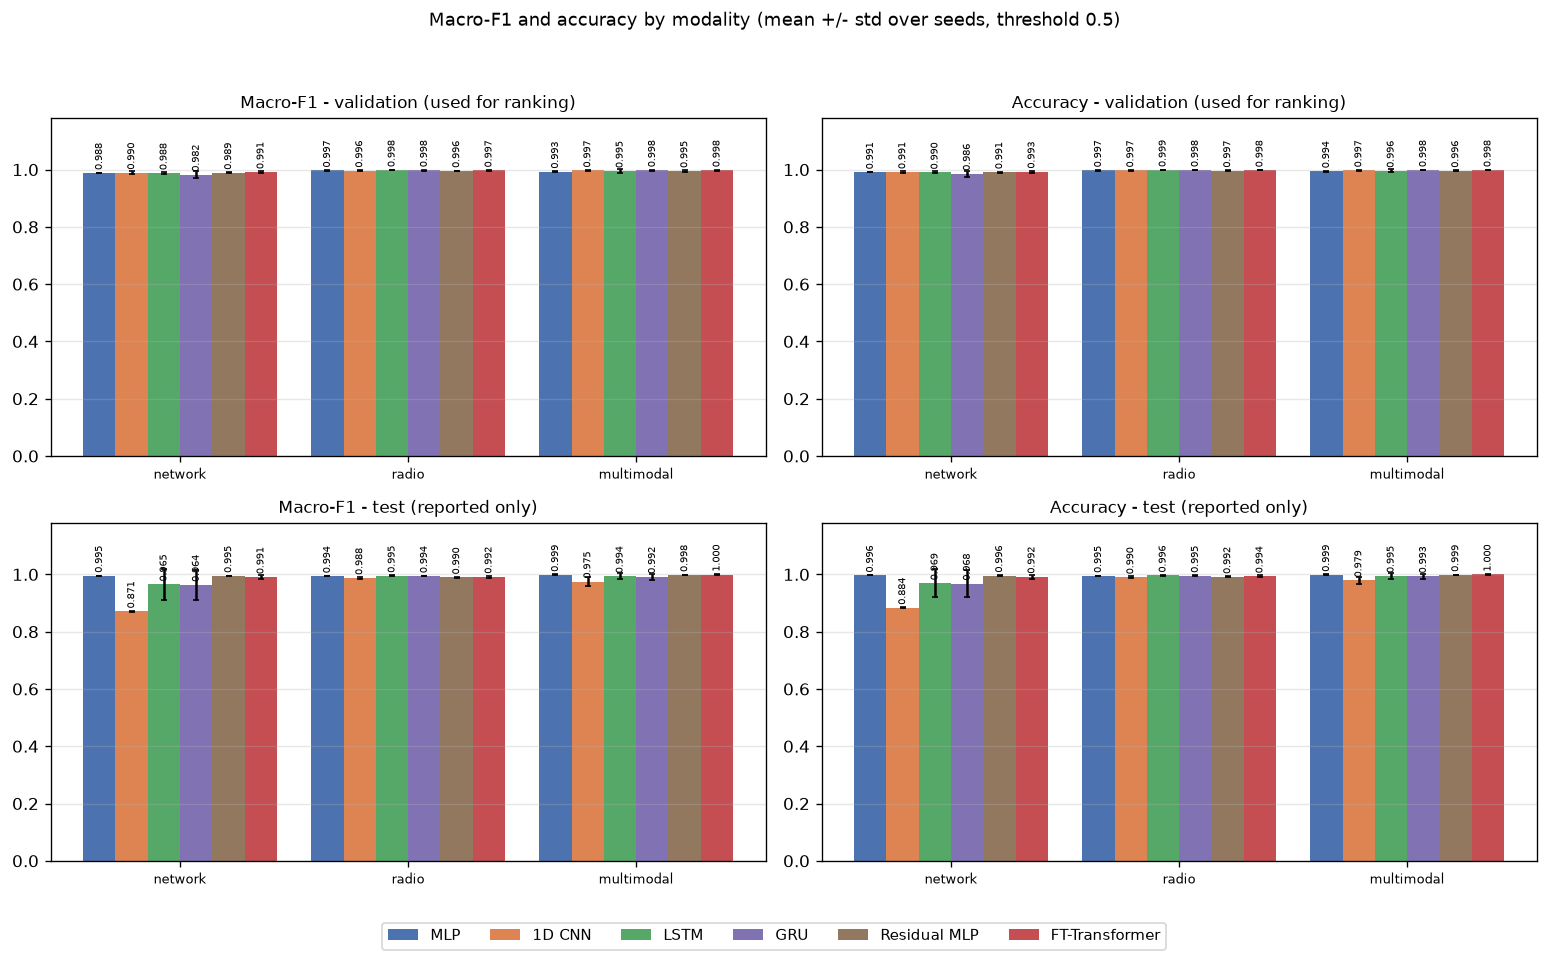

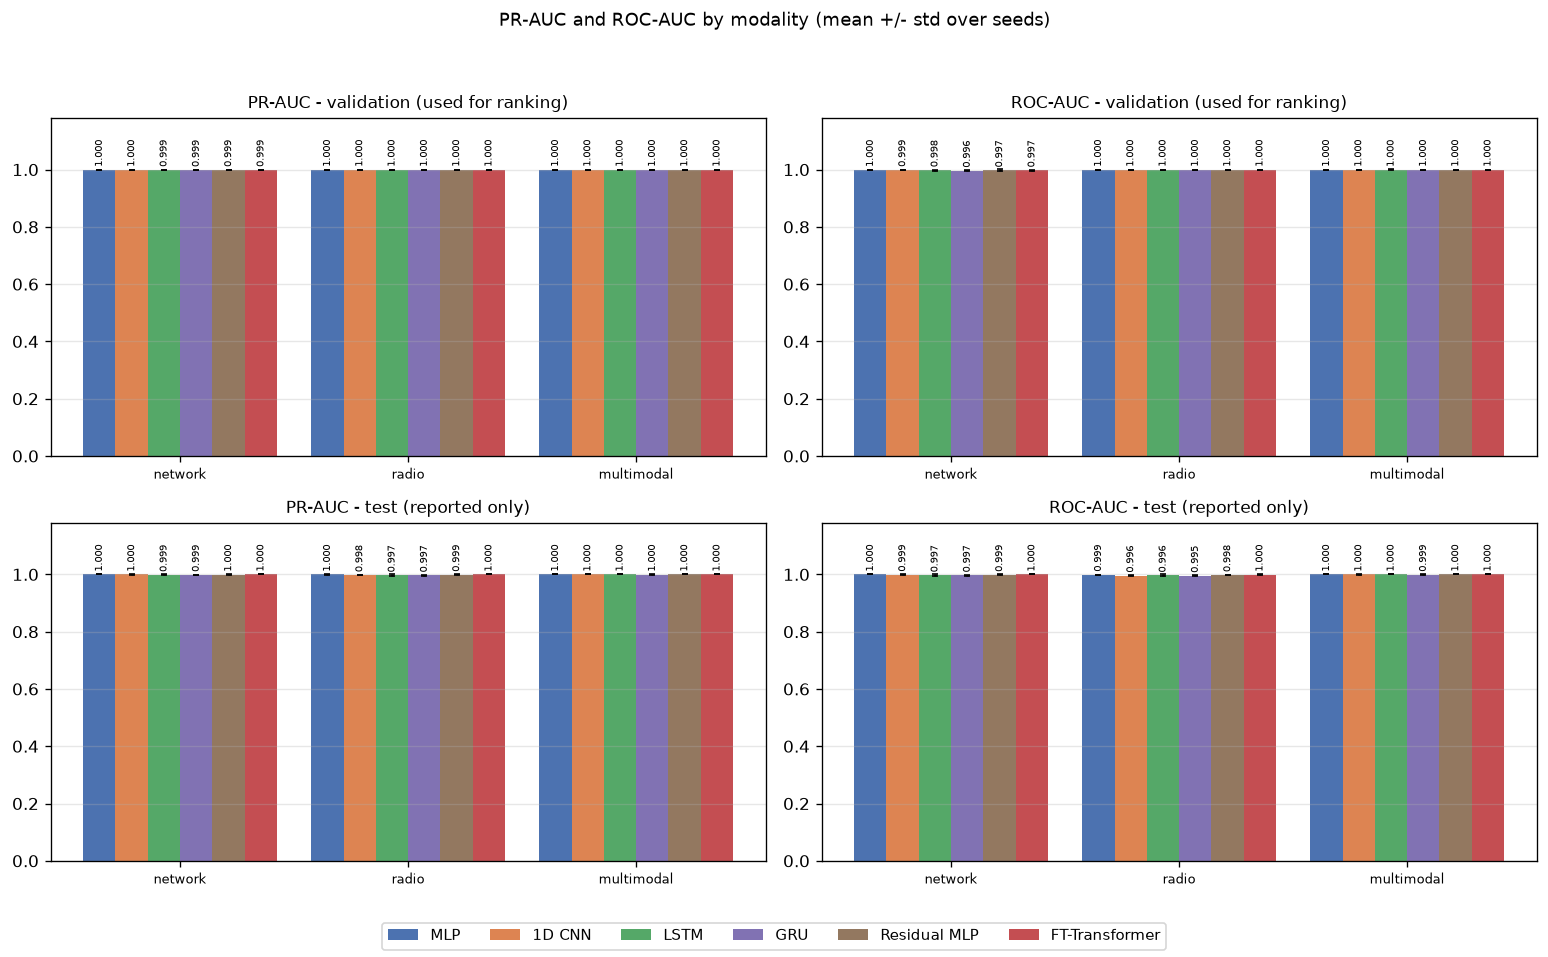

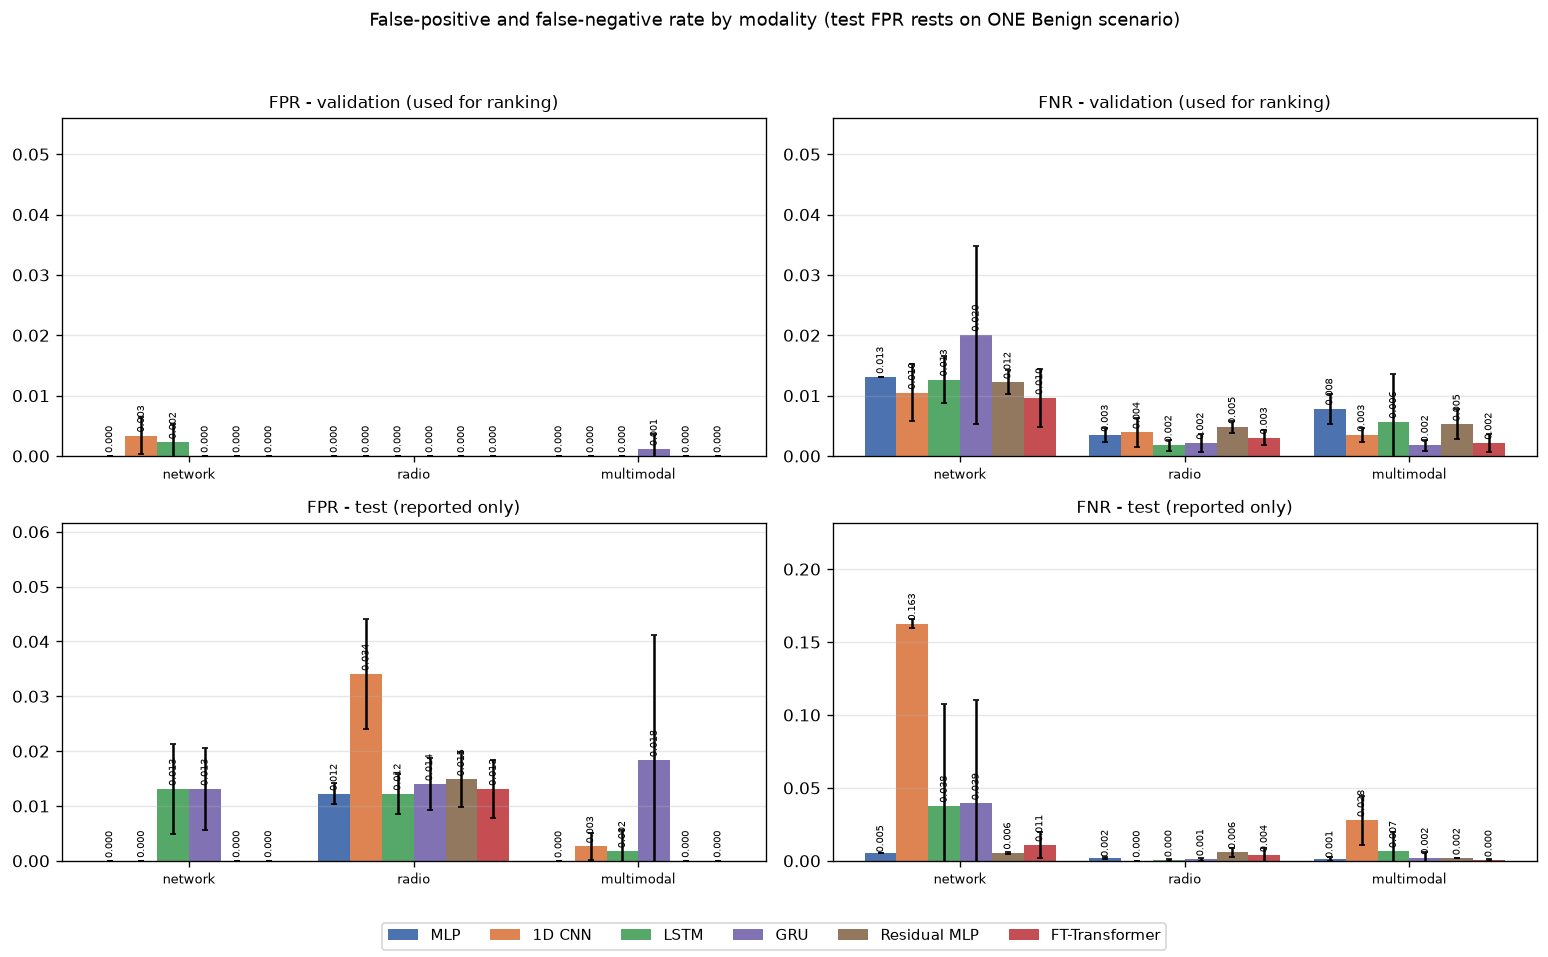

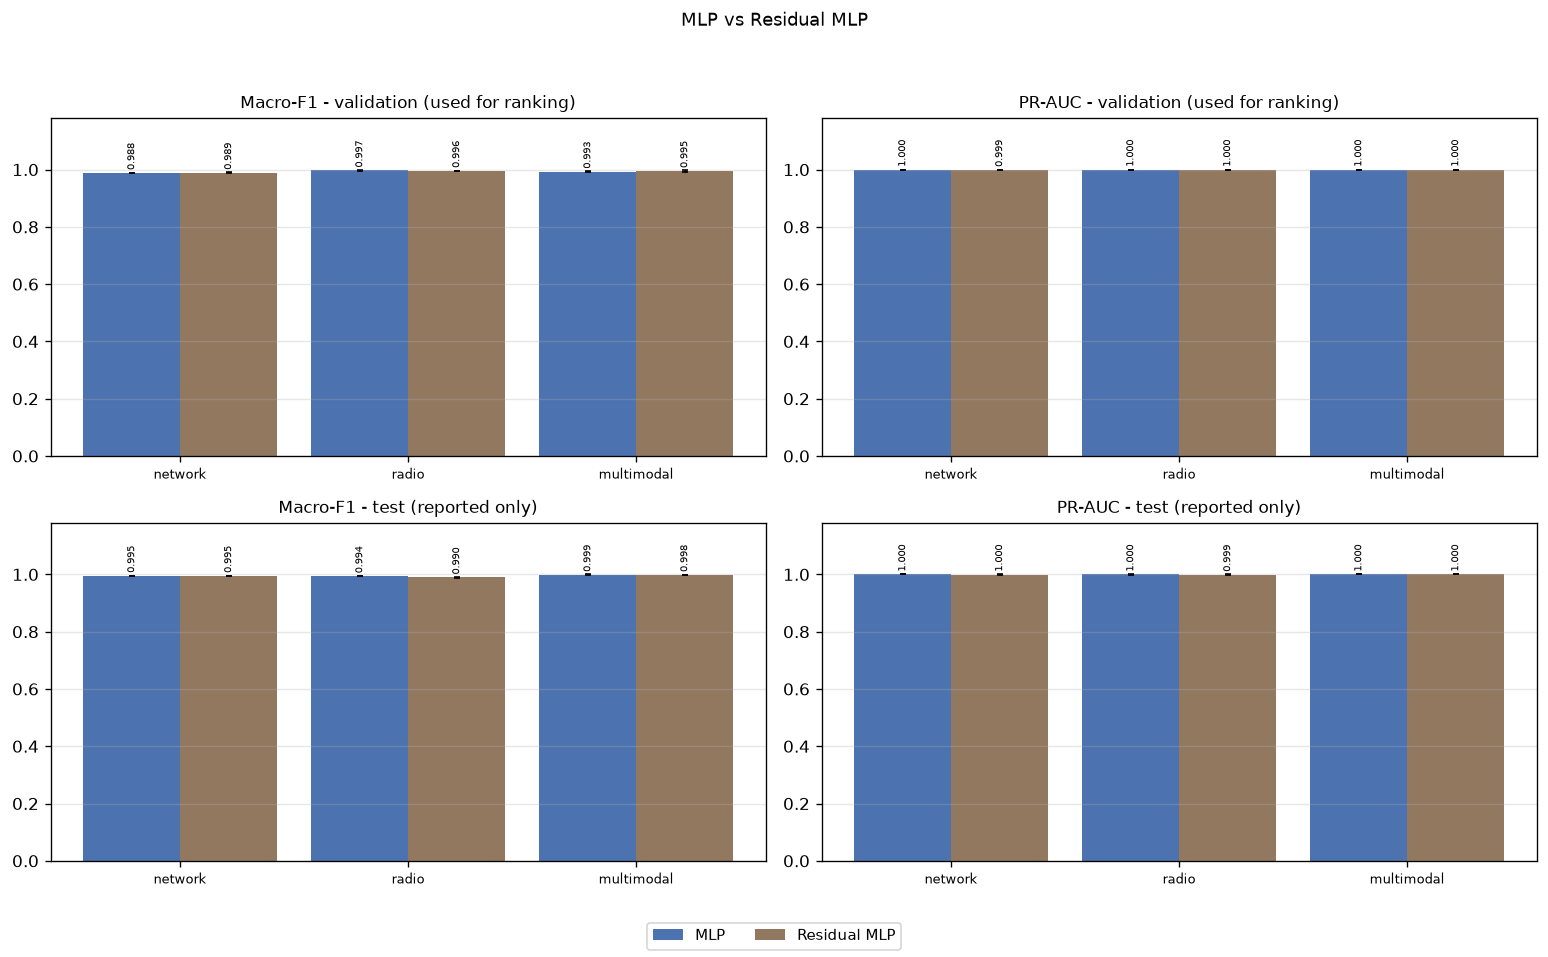

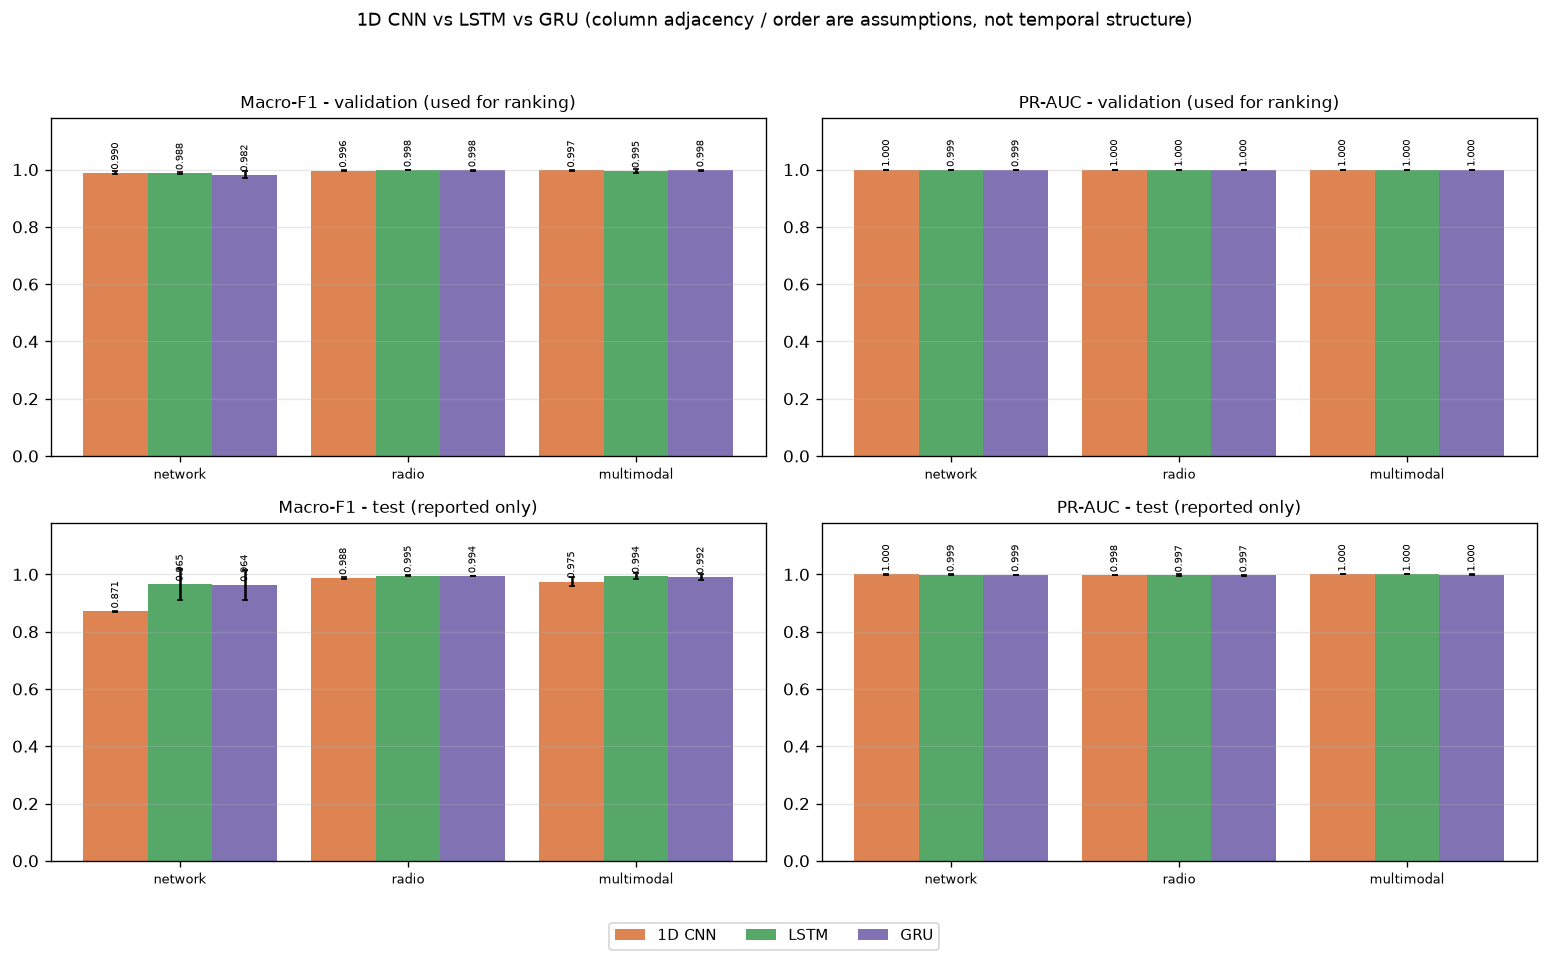

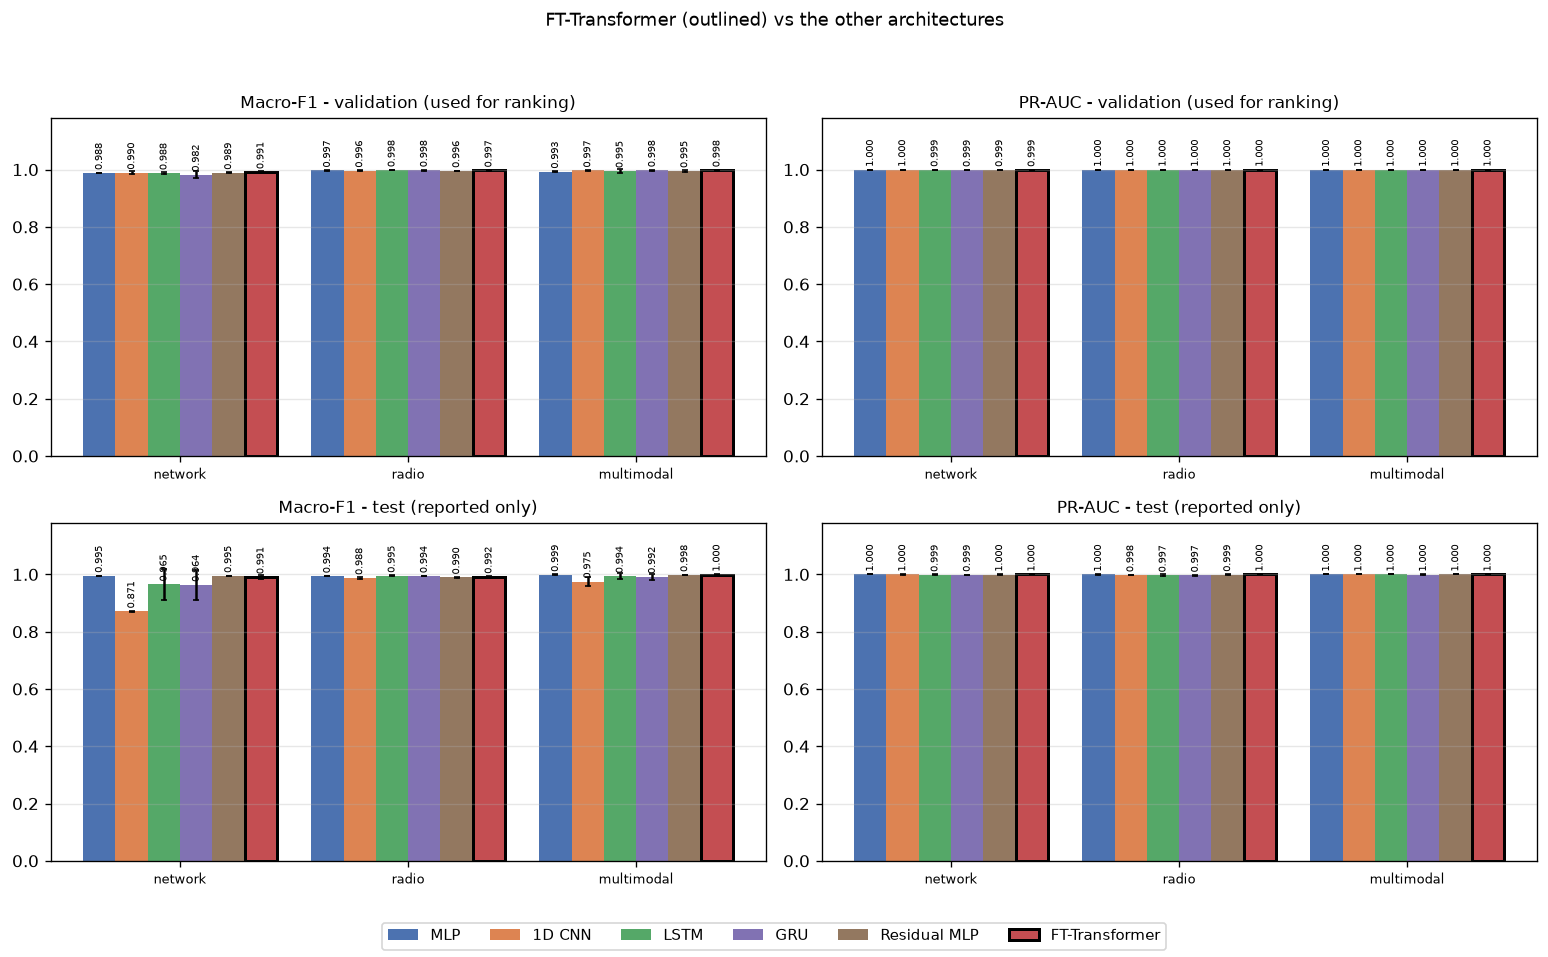

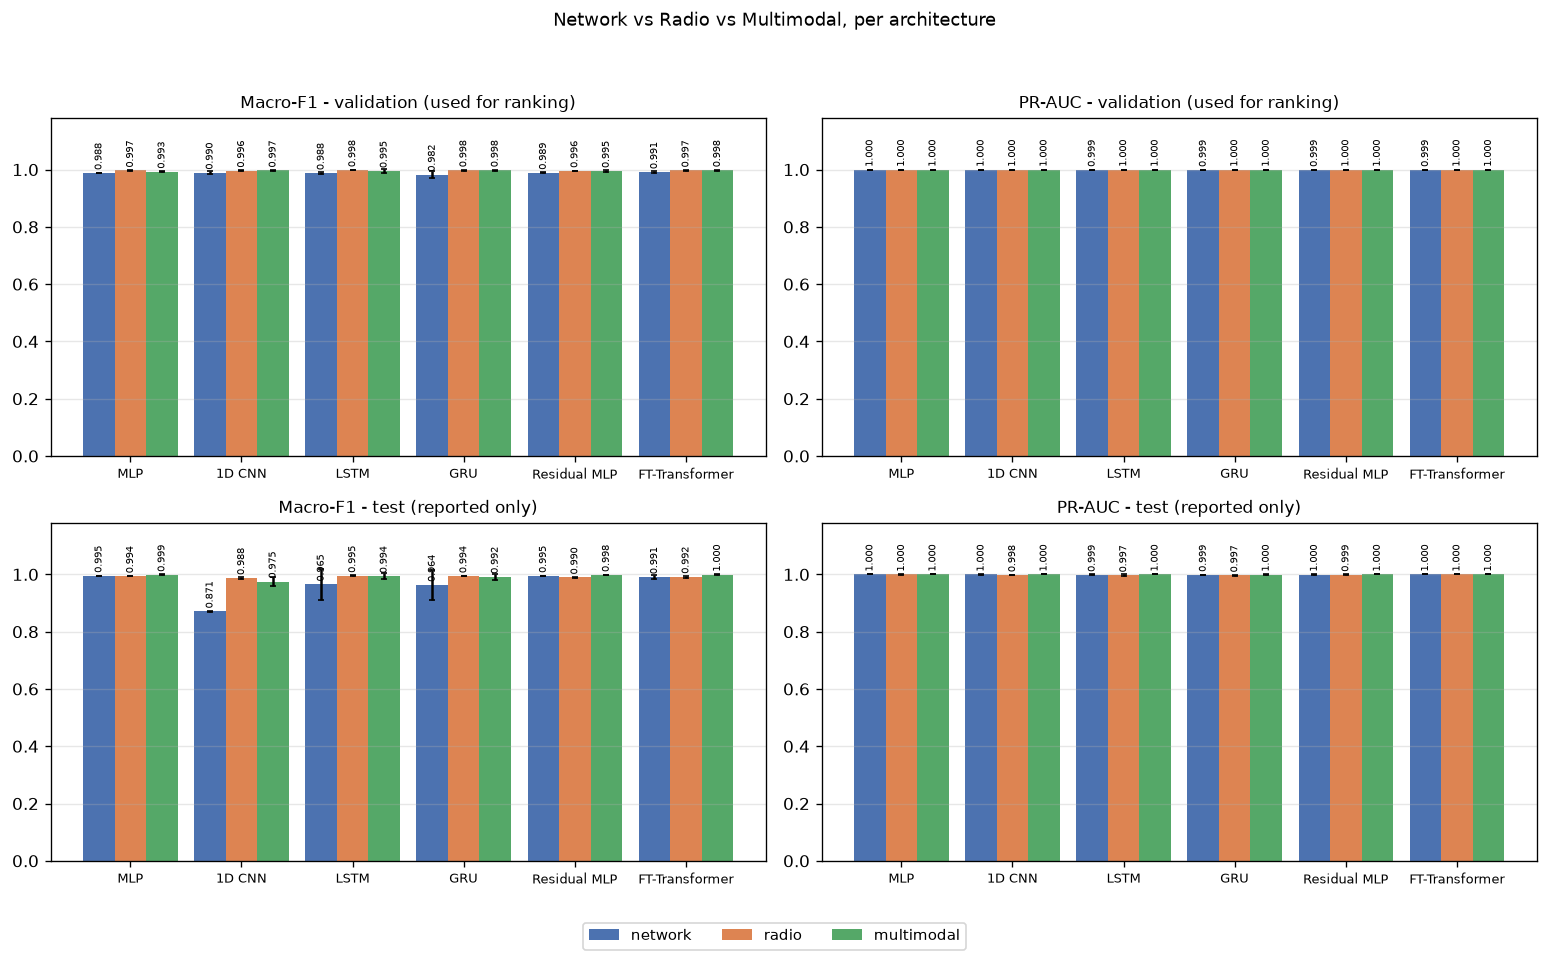

In [29]:
# ---- 19a. Plot helpers + comparison figures ----------------------------------------------------------------------------------------
ARCH_COLORS = {"mlp": "#4C72B0", "cnn": "#DD8452", "lstm": "#55A868", "gru": "#8172B3", "resmlp": "#937860", "ft_transformer": "#C44E52"}
MOD_COLORS = {"network": "#4C72B0", "radio": "#DD8452", "multimodal": "#55A868"}
METRIC_TITLE = {"macro_f1": "Macro-F1", "accuracy": "Accuracy", "pr_auc": "PR-AUC", "roc_auc": "ROC-AUC", "fpr": "FPR", "fnr": "FNR", "precision": "Precision", "recall": "Recall"}
def _save(fig, name):
    fig.savefig(RESULTS_OUT / name, dpi=120, bbox_inches="tight"); plt.close(fig); display(Image(filename=str(RESULTS_OUT / name)))
def bar_panel(ax, S, part, metric, groups, hues, group_col, hue_col, hue_label, hue_colors, highlight=None):
    x = np.arange(len(groups)); w = 0.85 / len(hues); top = 1.0
    for j, h in enumerate(hues):
        rows = [S[(S[group_col] == g) & (S[hue_col] == h)].iloc[0] for g in groups]
        vals = np.array([r[f"{part}_{metric}_mean"] for r in rows]); errs = np.nan_to_num(np.array([r[f"{part}_{metric}_std"] for r in rows]))
        if metric in ("fpr", "fnr"): top = max(top if top != 1.0 else 0.0, float((vals + errs).max()) * 1.25, 0.05)
        bars = ax.bar(x + j * w - 0.425 + w / 2, vals, w, yerr=errs, capsize=2, color=hue_colors[h], label=hue_label(h),
                      edgecolor="black" if highlight == h else "none", linewidth=1.8 if highlight == h else 0)
        for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + top * 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=6, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels([str(g) if group_col == "modality" else ARCH_LABEL[g] for g in groups], fontsize=8); ax.set_ylim(0, top * 1.12 if metric in ("fpr", "fnr") else 1.18)
    ax.grid(axis="y", alpha=0.3)
def metric_figure(name, metrics, archs, title, group_col="modality", highlight=None):
    hue_col = "architecture" if group_col == "modality" else "modality"
    groups = MODALITIES if group_col == "modality" else archs; hues = archs if group_col == "modality" else MODALITIES
    hue_label = (lambda h: ARCH_LABEL[h]) if group_col == "modality" else (lambda h: h); hue_colors = ARCH_COLORS if group_col == "modality" else MOD_COLORS
    S = SUMMARY[SUMMARY["architecture"].isin(archs)]
    fig, axes = plt.subplots(2, len(metrics), figsize=(6.5 * len(metrics), 8), squeeze=False)
    for ri, (part, pt) in enumerate([("val", "validation (used for ranking)"), ("test", "test (reported only)")]):
        for ci, mk in enumerate(metrics):
            bar_panel(axes[ri, ci], S, part, mk, groups, hues, group_col, hue_col, hue_label, hue_colors, highlight); axes[ri, ci].set_title(f"{METRIC_TITLE[mk]} - {pt}", fontsize=10)
    h, l = axes[0, 0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=len(hues), fontsize=9)
    fig.suptitle(title + ("  [SMOKE TEST - meaningless numbers]" if SMOKE_TEST else ""), fontsize=11); fig.tight_layout(rect=[0, 0.05, 1, 0.95]); _save(fig, name)
metric_figure("fig_macro_f1_accuracy.png", ["macro_f1", "accuracy"], ARCHS, "Macro-F1 and accuracy by modality (mean +/- std over seeds, threshold 0.5)")
metric_figure("fig_pr_auc_roc_auc.png", ["pr_auc", "roc_auc"], ARCHS, "PR-AUC and ROC-AUC by modality (mean +/- std over seeds)")
metric_figure("fig_fpr_fnr.png", ["fpr", "fnr"], ARCHS, "False-positive and false-negative rate by modality (test FPR rests on ONE Benign scenario)")
metric_figure("fig_mlp_vs_resmlp.png", ["macro_f1", "pr_auc"], ["mlp", "resmlp"], "MLP vs Residual MLP")
metric_figure("fig_cnn_vs_lstm_vs_gru.png", ["macro_f1", "pr_auc"], ["cnn", "lstm", "gru"], "1D CNN vs LSTM vs GRU (column adjacency / order are assumptions, not temporal structure)")
metric_figure("fig_ft_transformer_vs_others.png", ["macro_f1", "pr_auc"], ARCHS, "FT-Transformer (outlined) vs the other architectures", highlight="ft_transformer")
metric_figure("fig_modality_comparison.png", ["macro_f1", "pr_auc"], ARCHS, "Network vs Radio vs Multimodal, per architecture", group_col="architecture")

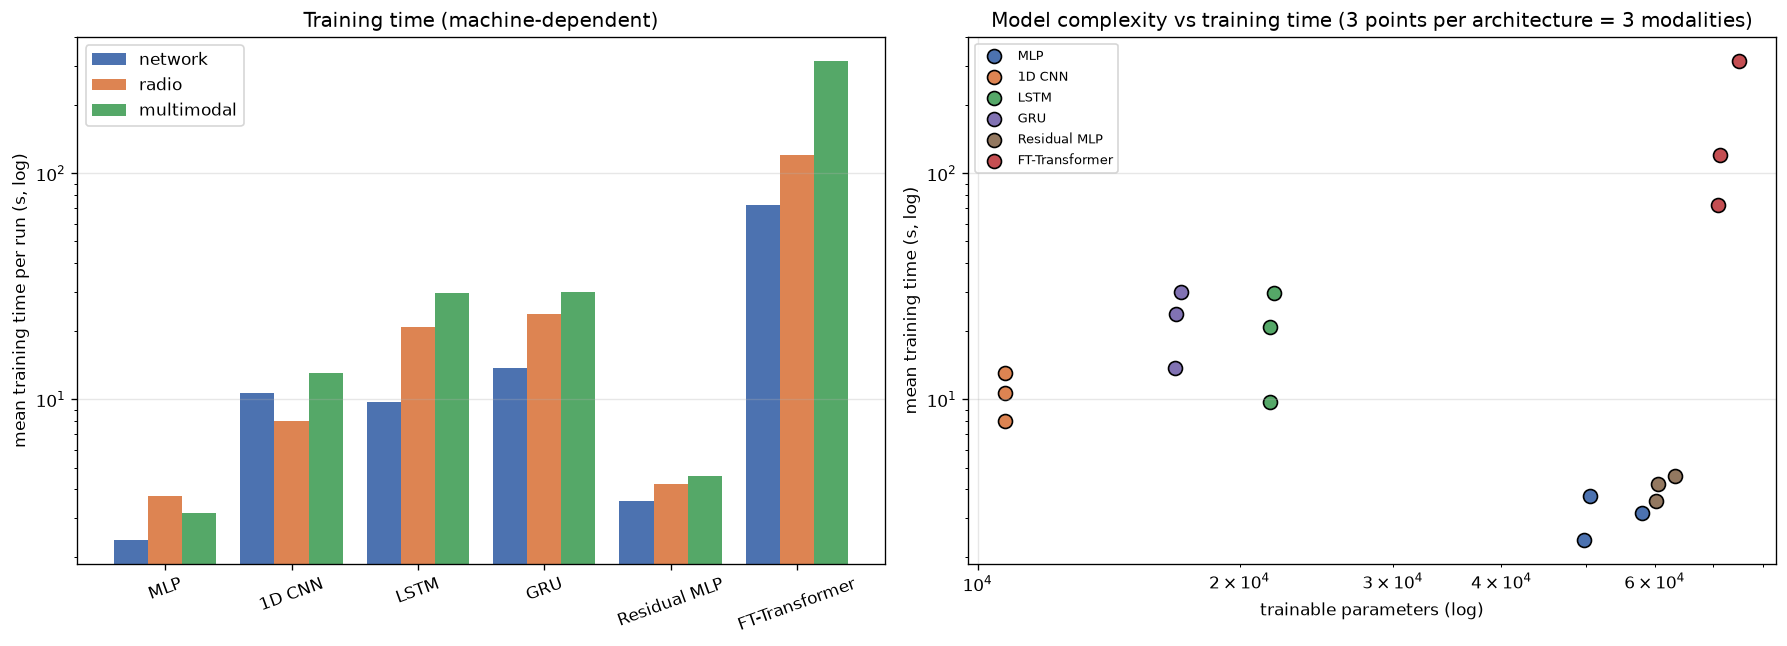

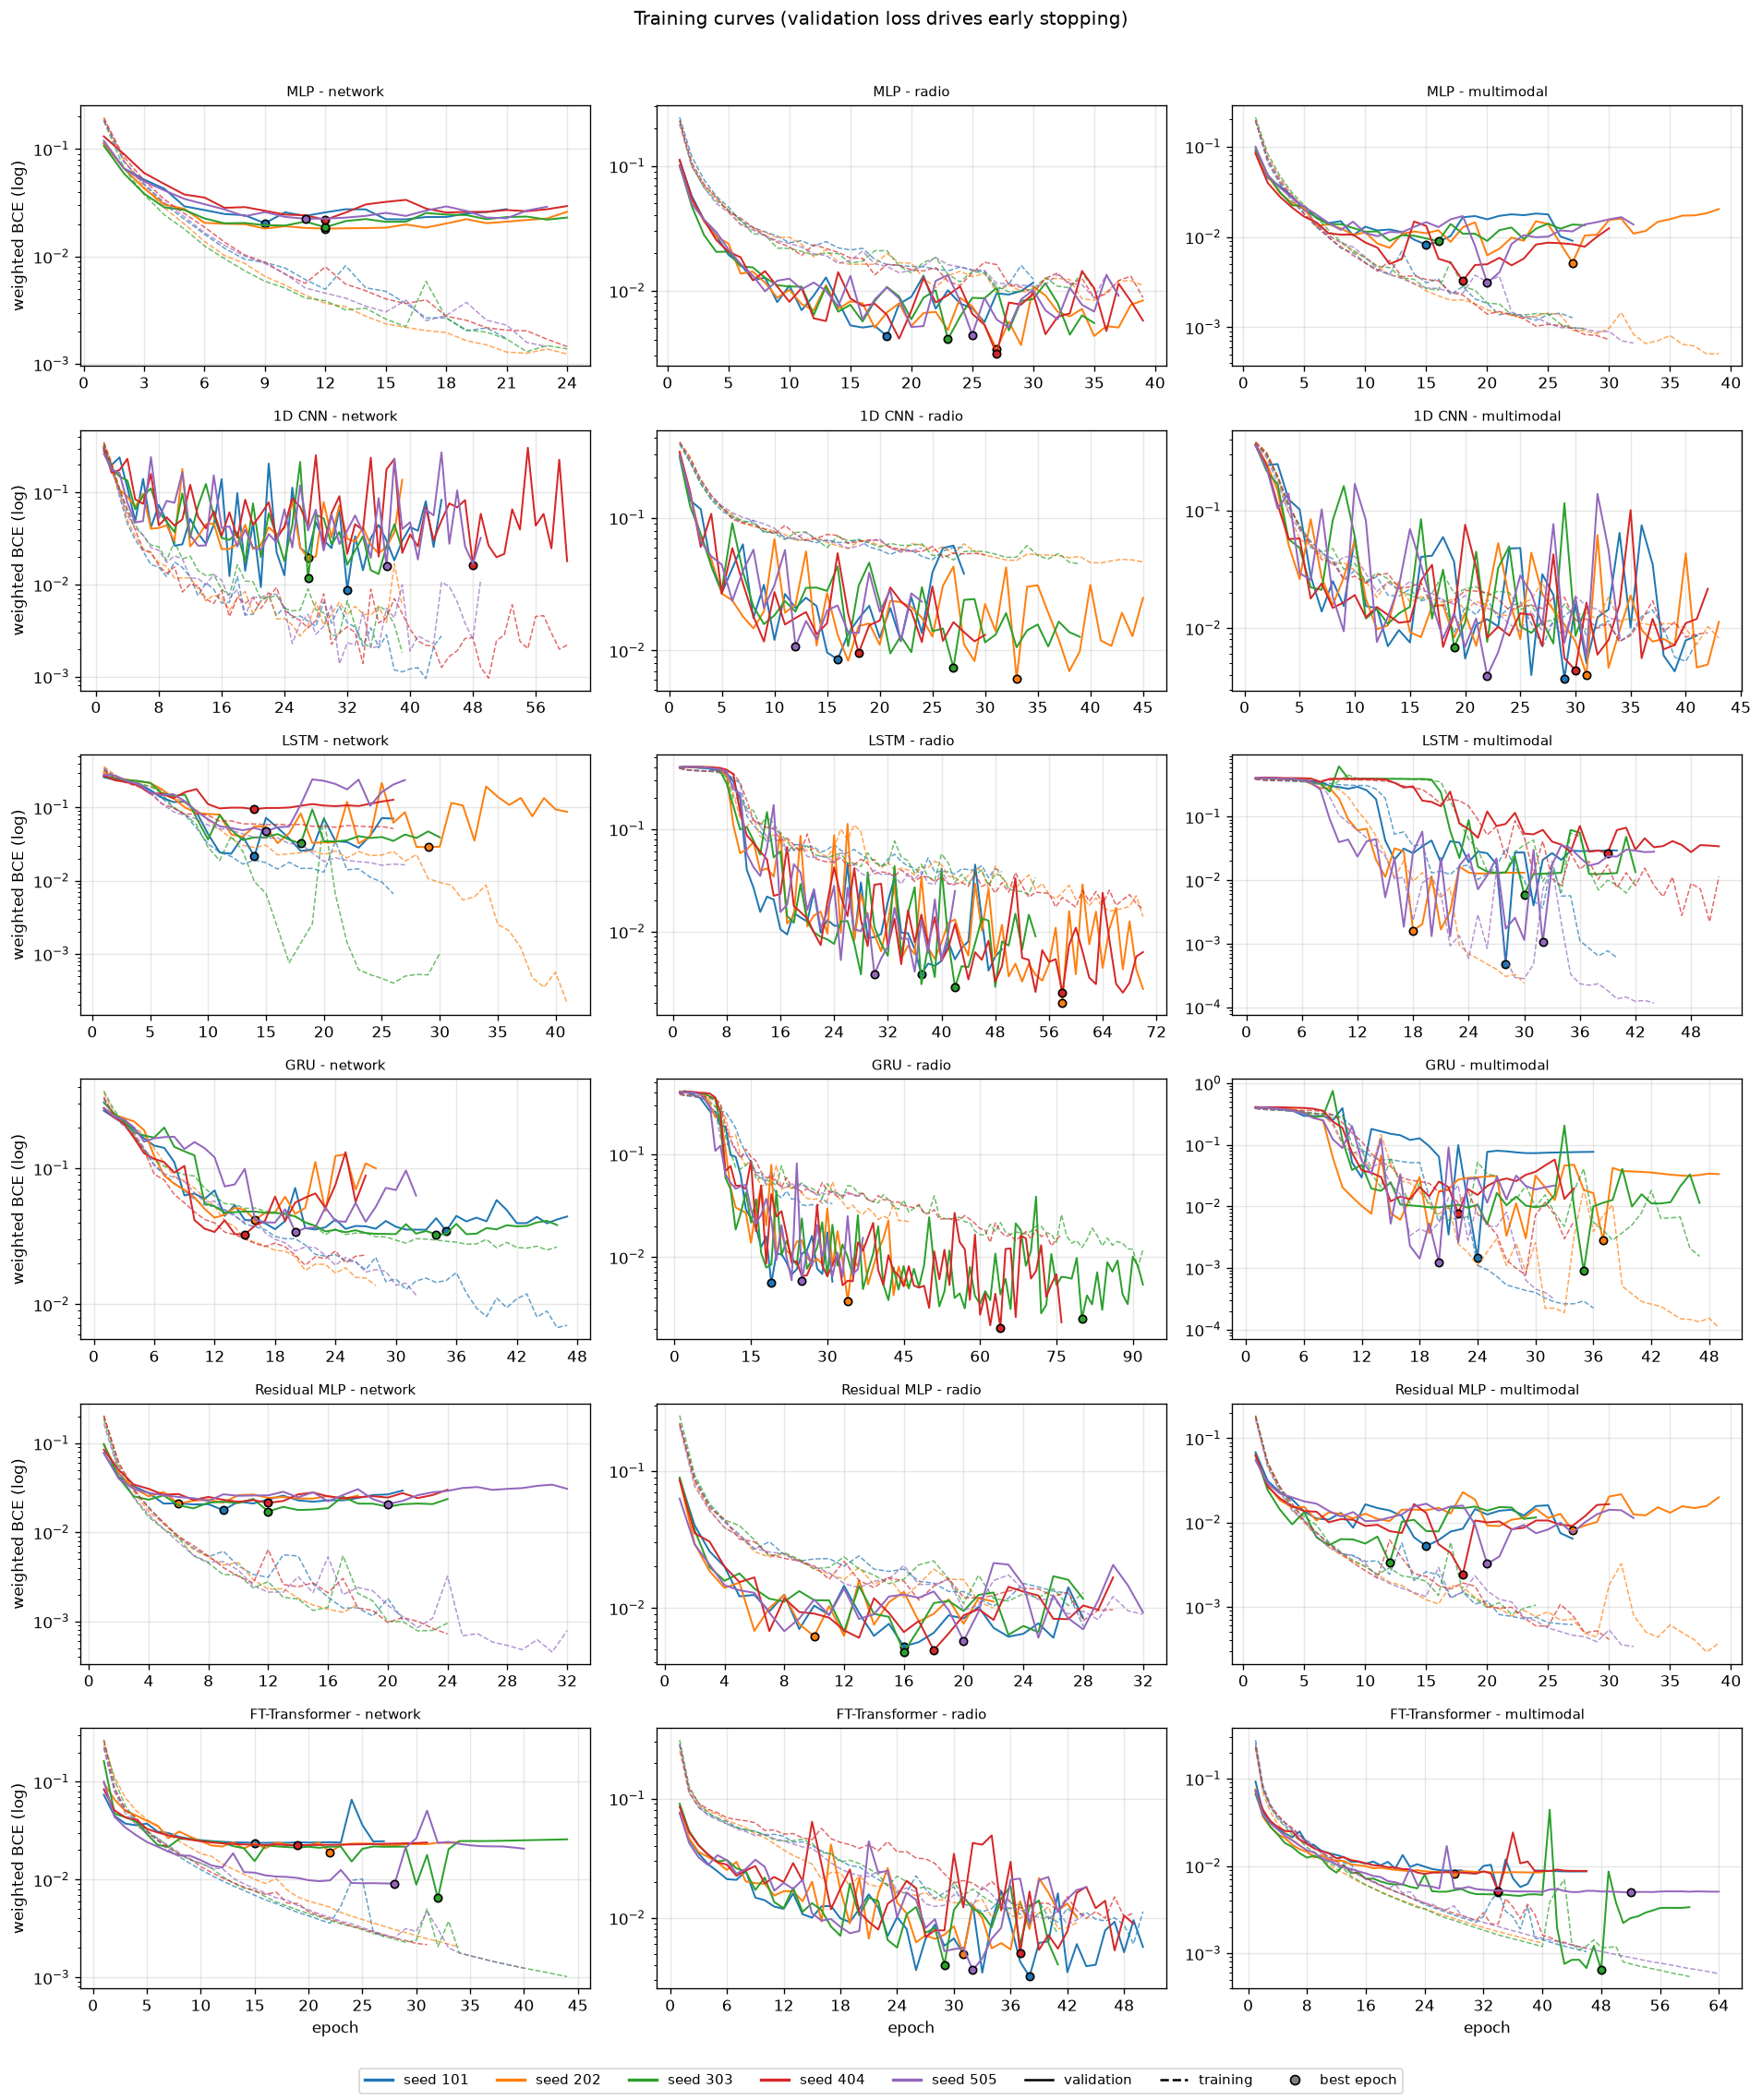

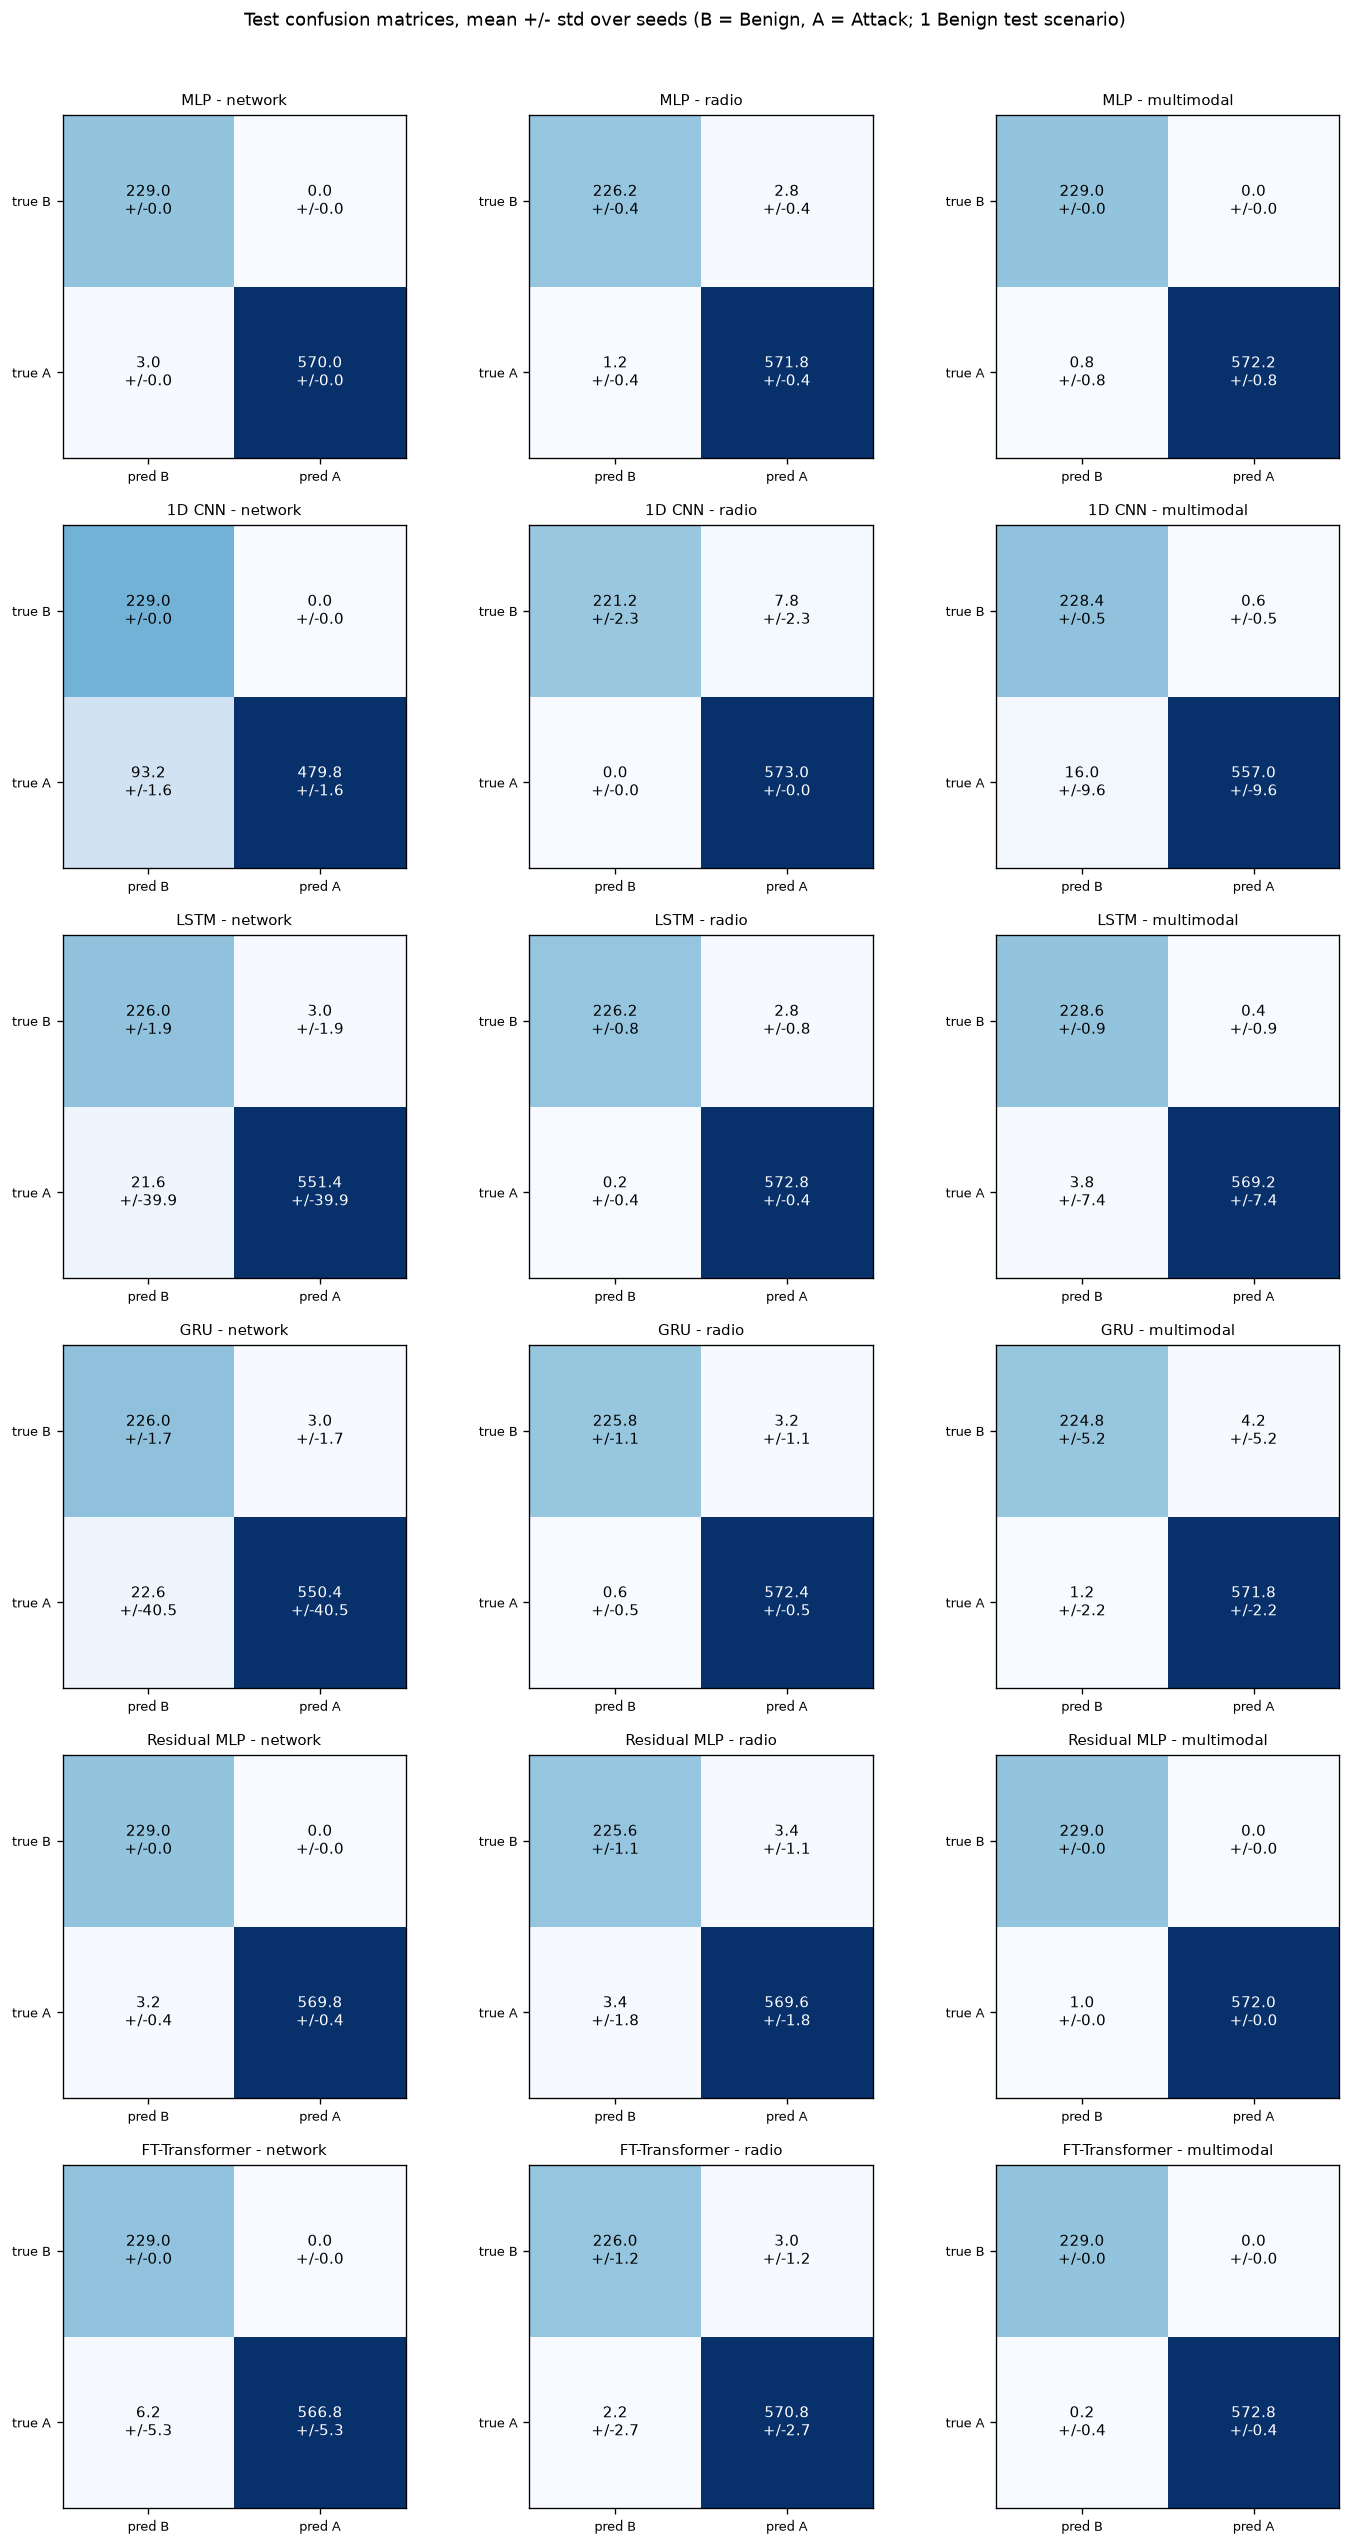

In [30]:
# ---- 19b. Training time / complexity, training curves, confusion matrices ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bar_panel_data = SUMMARY.pivot(index="architecture", columns="modality", values="train_time_s_mean").reindex(ARCHS)
x = np.arange(len(ARCHS)); w = 0.27
for j, m in enumerate(MODALITIES): axes[0].bar(x + j * w - w, bar_panel_data[m].to_numpy(), w, color=MOD_COLORS[m], label=m)
axes[0].set_yscale("log"); axes[0].set_xticks(x); axes[0].set_xticklabels([ARCH_LABEL[a] for a in ARCHS], rotation=20); axes[0].set_ylabel("mean training time per run (s, log)"); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("Training time (machine-dependent)")
for a in ARCHS:
    g = SUMMARY[SUMMARY.architecture == a]; axes[1].scatter(g["n_params"], g["train_time_s_mean"], s=70, color=ARCH_COLORS[a], label=ARCH_LABEL[a], edgecolor="black")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("trainable parameters (log)"); axes[1].set_ylabel("mean training time (s, log)"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
axes[1].set_title("Model complexity vs training time (3 points per architecture = 3 modalities)")
fig.tight_layout(); _save(fig, "fig_training_time_complexity.png")

SEED_COLORS = {s: plt.cm.tab10(i) for i, s in enumerate(SEEDS)}
fig, axes = plt.subplots(len(ARCHS), 3, figsize=(16, 3.2 * len(ARCHS)))
for ri, a in enumerate(ARCHS):
    for ci, m in enumerate(MODALITIES):
        ax = axes[ri, ci]
        for s in SEEDS:
            h = HIST[(HIST.architecture == a) & (HIST.modality == m) & (HIST.seed == s)]
            ax.plot(h["epoch"], h["val_loss"], "-", color=SEED_COLORS[s], lw=1.2); ax.plot(h["epoch"], h["train_loss"], "--", color=SEED_COLORS[s], lw=0.9, alpha=0.7)
            b = h[h["is_best_epoch"]]; ax.plot(b["epoch"], b["val_loss"], "o", color=SEED_COLORS[s], ms=5, mec="black")
        ax.set_yscale("log"); ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True)); ax.grid(alpha=0.3); ax.set_title(f"{ARCH_LABEL[a]} - {m}", fontsize=9)
        if ci == 0: ax.set_ylabel("weighted BCE (log)")
        if ri == len(ARCHS) - 1: ax.set_xlabel("epoch")
handles = [Line2D([0], [0], color=SEED_COLORS[s], lw=2, label=f"seed {s}") for s in SEEDS] + [Line2D([0], [0], color="k", ls="-", label="validation"), Line2D([0], [0], color="k", ls="--", label="training"), Line2D([0], [0], marker="o", color="w", mfc="grey", mec="k", label="best epoch")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=9); fig.suptitle("Training curves (validation loss drives early stopping)" + (" [SMOKE TEST]" if SMOKE_TEST else ""), fontsize=12)
fig.tight_layout(rect=[0, 0.02, 1, 0.97]); _save(fig, "training_curves.png")

fig, axes = plt.subplots(len(ARCHS), 3, figsize=(12, 3.6 * len(ARCHS)))
for ri, a in enumerate(ARCHS):
    for ci, m in enumerate(MODALITIES):
        g = PER_SEED[(PER_SEED.architecture == a) & (PER_SEED.modality == m)]
        mean = np.array([[g.test_tn.mean(), g.test_fp.mean()], [g.test_fn.mean(), g.test_tp.mean()]]); sd = np.array([[g[c].std(ddof=1) if len(g) > 1 else 0.0 for c in ("test_tn", "test_fp")], [g[c].std(ddof=1) if len(g) > 1 else 0.0 for c in ("test_fn", "test_tp")]])
        ax = axes[ri, ci]; ax.imshow(mean, cmap="Blues", vmin=0, vmax=max(1.0, mean.max()))
        for i in range(2):
            for j in range(2): ax.text(j, i, f"{mean[i, j]:.1f}\n+/-{sd[i, j]:.1f}", ha="center", va="center", fontsize=9, color="white" if mean[i, j] > 0.6 * mean.max() else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred B", "pred A"], fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(["true B", "true A"], fontsize=8); ax.set_title(f"{ARCH_LABEL[a]} - {m}", fontsize=9)
fig.suptitle("Test confusion matrices, mean +/- std over seeds (B = Benign, A = Attack; 1 Benign test scenario)" + (" [SMOKE TEST]" if SMOKE_TEST else ""), fontsize=11); fig.tight_layout(rect=[0, 0, 1, 0.97]); _save(fig, "confusion_matrices.png")

In [31]:
# ---- 19c. Final comparison - strongest models by VALIDATION metrics only ---------------------------------------------------------------
# ranking rule (declared in advance): validation macro-F1 (mean over seeds, higher) > validation PR-AUC (higher) > best validation loss (lower) > fewer parameters
def rank_by_validation(S):
    rows = []
    for m in MODALITIES:
        g = S[S.modality == m].sort_values(["val_macro_f1_mean", "val_pr_auc_mean", "best_val_loss_mean", "n_params"], ascending=[False, False, True, True]).reset_index(drop=True)
        g["validation_rank"] = np.arange(1, len(g) + 1); rows.append(g)
    return pd.concat(rows, ignore_index=True)
RANKED = rank_by_validation(SUMMARY)
pm = lambda mu, sd, nd=4: f"{mu:.{nd}f} +/- {sd:.{nd}f}" if np.isfinite(sd) else f"{mu:.{nd}f}"
FINAL_VALIDATION_TABLE = pd.DataFrame([{"modality": r.modality, "validation_rank": r.validation_rank, "architecture": ARCH_LABEL[r.architecture], "val macro-F1": pm(r.val_macro_f1_mean, r.val_macro_f1_std),
        "val PR-AUC": pm(r.val_pr_auc_mean, r.val_pr_auc_std), "val ROC-AUC": pm(r.val_roc_auc_mean, r.val_roc_auc_std), "val FPR": pm(r.val_fpr_mean, r.val_fpr_std), "val FNR": pm(r.val_fnr_mean, r.val_fnr_std),
        "best val loss": pm(r.best_val_loss_mean, r.best_val_loss_std), "parameters": r.n_params, "train time (s)": round(r.train_time_s_mean, 1)} for r in RANKED.itertuples()])
print("FINAL COMPARISON - ranking by VALIDATION metrics only (per modality):"); display(FINAL_VALIDATION_TABLE)
OVERALL = RANKED.groupby("architecture").agg(mean_validation_rank=("validation_rank", "mean"), best_rank=("validation_rank", "min"), mean_val_macro_f1=("val_macro_f1_mean", "mean")).reset_index().sort_values(["mean_validation_rank", "mean_val_macro_f1"], ascending=[True, False])
OVERALL["architecture"] = OVERALL["architecture"].map(ARCH_LABEL); print("mean validation rank across the three modalities (lower = better):"); display(OVERALL.round(4))
TEST_REPORT_TABLE = pd.DataFrame([{"modality": r.modality, "architecture": ARCH_LABEL[r.architecture], "validation_rank": r.validation_rank, "test accuracy": pm(r.test_accuracy_mean, r.test_accuracy_std), "test macro-F1": pm(r.test_macro_f1_mean, r.test_macro_f1_std),
        "test PR-AUC": pm(r.test_pr_auc_mean, r.test_pr_auc_std), "test ROC-AUC": pm(r.test_roc_auc_mean, r.test_roc_auc_std), "test FPR": pm(r.test_fpr_mean, r.test_fpr_std), "test FNR": pm(r.test_fnr_mean, r.test_fnr_std)} for r in RANKED.itertuples()])
print("TEST metrics (reported for transparency; NOT used for ranking or selection):"); display(TEST_REPORT_TABLE)

FINAL COMPARISON - ranking by VALIDATION metrics only (per modality):


,modality,validation_rank,architecture,val macro-F1,val PR-AUC,val ROC-AUC,val FPR,val FNR,best val loss,parameters,train time (s)
0,network,1,FT-Transformer,0.9915 +/- 0.0042,0.9993 +/- 0.0007,0.9975 +/- 0.0023,0.0000 +/- 0.0000,0.0096 +/- 0.0048,0.0162 +/- 0.0079,70913,72.6
1,network,2,1D CNN,0.9895 +/- 0.0044,0.9998 +/- 0.0001,0.9994 +/- 0.0004,0.0034 +/- 0.0031,0.0105 +/- 0.0047,0.0144 +/- 0.0042,10753,10.7
2,network,3,Residual MLP,0.9891 +/- 0.0017,0.9992 +/- 0.0010,0.9974 +/- 0.0035,0.0000 +/- 0.0000,0.0122 +/- 0.0020,0.0196 +/- 0.0020,60193,3.5
3,network,4,MLP,0.9884 +/- 0.0000,0.9998 +/- 0.0003,0.9995 +/- 0.0007,0.0000 +/- 0.0000,0.0131 +/- 0.0000,0.0203 +/- 0.0019,49793,2.4
4,network,5,LSTM,0.9880 +/- 0.0044,0.9994 +/- 0.0005,0.9982 +/- 0.0015,0.0023 +/- 0.0031,0.0127 +/- 0.0039,0.0450 +/- 0.0295,21673,9.7
5,network,6,GRU,0.9824 +/- 0.0127,0.9989 +/- 0.0008,0.9965 +/- 0.0030,0.0000 +/- 0.0000,0.0201 +/- 0.0148,0.0352 +/- 0.0038,16873,13.8
6,radio,1,LSTM,0.9984 +/- 0.0009,1.0000 +/- 0.0000,1.0000 +/- 0.0000,0.0000 +/- 0.0000,0.0017 +/- 0.0010,0.0030 +/- 0.0008,21697,20.9
7,radio,2,GRU,0.9980 +/- 0.0014,1.0000 +/- 0.0000,1.0000 +/- 0.0000,0.0000 +/- 0.0000,0.0022 +/- 0.0015,0.0039 +/- 0.0017,16897,23.8
8,radio,3,FT-Transformer,0.9973 +/- 0.0011,1.0000 +/- 0.0000,1.0000 +/- 0.0000,0.0000 +/- 0.0000,0.0031 +/- 0.0012,0.0042 +/- 0.0008,71297,120.4
9,radio,4,MLP,0.9969 +/- 0.0011,1.0000 +/- 0.0000,1.0000 +/- 0.0000,0.0000 +/- 0.0000,0.0035 +/- 0.0012,0.0039 +/- 0.0006,50561,3.7


mean validation rank across the three modalities (lower = better):


,architecture,mean_validation_rank,best_rank,mean_val_macro_f1
1,FT-Transformer,1.6667,1,0.9956
0,1D CNN,3.3333,2,0.9943
2,GRU,3.3333,2,0.9928
3,LSTM,3.6667,1,0.9938
5,Residual MLP,4.3333,3,0.9934
4,MLP,4.6667,4,0.9927


TEST metrics (reported for transparency; NOT used for ranking or selection):


,modality,architecture,validation_rank,test accuracy,test macro-F1,test PR-AUC,test ROC-AUC,test FPR,test FNR
0,network,FT-Transformer,1,0.9923 +/- 0.0066,0.9906 +/- 0.0079,1.0000 +/- 0.0000,1.0000 +/- 0.0001,0.0000 +/- 0.0000,0.0108 +/- 0.0092
1,network,1D CNN,2,0.8838 +/- 0.0020,0.8712 +/- 0.0021,0.9998 +/- 0.0003,0.9995 +/- 0.0007,0.0000 +/- 0.0000,0.1627 +/- 0.0029
2,network,Residual MLP,3,0.9960 +/- 0.0006,0.9951 +/- 0.0007,0.9996 +/- 0.0006,0.9988 +/- 0.0020,0.0000 +/- 0.0000,0.0056 +/- 0.0008
3,network,MLP,4,0.9963 +/- 0.0000,0.9954 +/- 0.0000,1.0000 +/- 0.0000,0.9999 +/- 0.0001,0.0000 +/- 0.0000,0.0052 +/- 0.0000
4,network,LSTM,5,0.9693 +/- 0.0498,0.9651 +/- 0.0550,0.9986 +/- 0.0015,0.9972 +/- 0.0027,0.0131 +/- 0.0082,0.0377 +/- 0.0697
5,network,GRU,6,0.9681 +/- 0.0484,0.9637 +/- 0.0530,0.9988 +/- 0.0005,0.9968 +/- 0.0014,0.0131 +/- 0.0076,0.0394 +/- 0.0706
6,radio,LSTM,1,0.9963 +/- 0.0015,0.9954 +/- 0.0019,0.9969 +/- 0.0036,0.9965 +/- 0.0035,0.0122 +/- 0.0037,0.0003 +/- 0.0008
7,radio,GRU,2,0.9953 +/- 0.0010,0.9942 +/- 0.0013,0.9968 +/- 0.0016,0.9954 +/- 0.0018,0.0140 +/- 0.0048,0.0010 +/- 0.0010
8,radio,FT-Transformer,3,0.9935 +/- 0.0028,0.9921 +/- 0.0035,0.9998 +/- 0.0001,0.9996 +/- 0.0002,0.0131 +/- 0.0053,0.0038 +/- 0.0047
9,radio,MLP,4,0.9950 +/- 0.0009,0.9939 +/- 0.0011,0.9997 +/- 0.0001,0.9994 +/- 0.0002,0.0122 +/- 0.0020,0.0021 +/- 0.0008


## 20. Research limitations and discussion

* **35 scenarios, only 6 Benign.** The split has 22 / 6 / 7 scenarios (train / validation / test); **each of the validation and test partitions contains a single Benign scenario**. False-positive rates are therefore estimated from one scenario each (resolution 1 / number of its windows), windows of a scenario are strongly dependent, and
  seed-to-seed spread is only initialisation variance - **not** a confidence interval for generalisation. The *validation-based ranking* rests on the same thin evidence and can be unstable.
* **Capture date / session is confounded with the class.** All Benign scenarios were captured on one date and no attack scenario was captured on that date (computed below). Scenario-grouped splitting stops windows of one scenario appearing in several partitions but **cannot remove** this confounding:
  a model can score highly by recognising capture conditions rather than attacks. **Labels are constant within each scenario.**
* **No claim of generalisation** to unseen 5G deployments, devices, sessions or attack implementations. High clean-data accuracy does **not** demonstrate it.
* **CNN, LSTM and GRU do not learn temporal dependencies here.** The feature columns are a fixed schema order, not a time axis. The CNN assumes adjacent columns are neighbours; the recurrent models read columns as arbitrary "steps". Their results are exploratory and must not be described as temporal learning.
* **One split, a-priori hyper-parameters, no tuning.** Another split or tuned settings could change the ranking. Differences of a few windows are within what this evaluation can resolve.
* **Heavy-tailed features** survive standardisation (no clipping was applied); neural networks may extrapolate poorly on such values.
* **The research objective is robustness to inference-time telemetry manipulation.** Clean-data comparison is one stage only; the checkpoints store what is needed for the next stage (feature order, preprocessing, training-set feature ranges, all seeds' weights), but **no manipulation, adversarial attack, trust score or defense is implemented or evaluated here.**
* Network-radio alignment is at the UTC-second level only; no packet-to-UE correspondence is claimed.

In [32]:
# ---- 20. Facts behind the limitations (computed from the data) --------------------------------------------------------------------------
dates = pd.to_datetime(df["timestamp_s"], unit="s", utc=True).dt.strftime("%Y-%m-%d")
scn_date = df.assign(_d=dates).groupby("scenario")["_d"].first(); scn_mode = df.groupby("scenario")["mode"].first()
benign_dates, attack_dates = sorted(scn_date[scn_mode == "Benign"].unique()), sorted(scn_date[scn_mode != "Benign"].unique())
print("Benign capture date(s):", benign_dates, "| attack capture dates:", attack_dates, "| shared by both classes:", sorted(set(benign_dates) & set(attack_dates)) or "none")
ben_part = {p: sorted(manifest[(manifest.partition == p) & (manifest.is_attack == 0)]["scenario"].unique()) for p in PARTS}
print("Benign scenarios per partition:", {p: (v, int(((manifest.partition == p) & (manifest.is_attack == 0)).sum())) for p, v in ben_part.items()})
ben_test = ben_part["test"]; n_ben_test = int(((manifest.partition == "test") & (manifest.is_attack == 0)).sum()); n_ben_val = int(((manifest.partition == "validation") & (manifest.is_attack == 0)).sum())
print(f"test FPR resolution = 1/{n_ben_test} = {1 / n_ben_test:.4f}; validation FPR resolution = 1/{n_ben_val} = {1 / n_ben_val:.4f}")

Benign capture date(s): ['2025-04-14'] | attack capture dates: ['2025-02-27', '2025-03-06', '2025-04-03'] | shared by both classes: none
Benign scenarios per partition: {'train': (['Benign1', 'Benign2', 'Benign5', 'Benign6'], 778), 'validation': (['Benign3'], 177), 'test': (['Benign4'], 229)}
test FPR resolution = 1/229 = 0.0044; validation FPR resolution = 1/177 = 0.0056


## 21. Exporting trained models and results
Written to `Models/deep_learning/comparison/` (a **sub-folder**, so nothing in `Models/deep_learning/` from earlier work is overwritten) and `Results/deep_learning_comparison/`.

**Checkpoints** (`<modality>_<architecture>.pt`, 18 files, loadable with `torch.load(..., weights_only=True)`) contain, for the later **inference-time telemetry-manipulation experiments**:
architecture name and configuration, the **tabular-to-model input representation**, feature names **in order**, the train-fitted **preprocessing parameters** (median / mean / scale), the **training-set range of every feature in raw units** (min, p01, p99, max - to bound plausible perturbations),
class weight, threshold, the weights of **all five seeds** with training metadata, and the validation-selected `primary_seed`. `dl_comparison_models.py` provides the model classes plus `load_checkpoint`, `apply_preprocessing`, `invert_preprocessing`, `predict_logits` and `predict_proba`
(raw telemetry in -> attack probability out; differentiable path via `model_from_checkpoint`).

In [33]:
# ---- 21. Export -------------------------------------------------------------------------------------------------------------------
(MODELS_OUT / "dl_comparison_models.py").write_text(LIB_SOURCE, encoding="utf-8")
INPUT_REPRESENTATION = {
    "mlp": "vector (B, F) of standardised features",
    "resmlp": "vector (B, F) of standardised features",
    "cnn": "(B, F) -> (B, 1, F): features in schema order treated as positions of a 1-channel signal (ASSUMPTION: adjacent columns are neighbours; not temporal)",
    "lstm": "(B, F) -> (B, F, 1+E): per position [standardised value, learnable feature-identity embedding]; positions are NOT time steps (exploratory)",
    "gru": "identical to the LSTM representation (exploratory)",
    "ft_transformer": "(B, F) -> per-feature tokens (B, F, d) + [CLS]; no positional encoding"}
ARCH_NOTES = {"cnn": "Do not interpret as temporal learning.", "lstm": "Exploratory; columns are not time steps.", "gru": "Exploratory; columns are not time steps."}
CKPT_FILES = {}
for a in ARCHS:
    for m in MODALITIES:
        ckpt = {"format_version": 1, "modality": m, "architecture": a, "architecture_label": ARCH_LABEL[a], "task": "binary intrusion detection, is_attack (0 = Benign, 1 = Attack = positive class)",
                "positive_class": 1, "threshold": THRESHOLD, "feature_names": list(FEATURES[m]), "n_features": len(FEATURES[m]), "feature_order": "fixed schema order = feature_names",
                "model_config": CONFIG["architectures"][a], "input_representation": INPUT_REPRESENTATION[a],
                "training_config": {**TRAIN, "lr_used": TRAIN["lr_overrides"].get(a, TRAIN["lr"])},
                "preprocessing": PREP[m], "feature_ranges_train_raw": RANGES[m], "class_weight": CLASS_WEIGHT,
                "primary_seed": PRIMARY_SEED[(a, m)], "seeds": list(SEEDS),
                "selection_rule": "primary_seed = lowest best validation loss among the seeds (validation only); headline results are 5-seed mean/std",
                "runs": {s: {"state_dict": RUNS[(a, m, s)]["state_dict"], "best_epoch": RUNS[(a, m, s)]["best_epoch"], "epochs_run": RUNS[(a, m, s)]["epochs_run"],
                             "best_val_loss": RUNS[(a, m, s)]["best_val_loss"], "train_time_s": RUNS[(a, m, s)]["train_time_s"]} for s in SEEDS},
                "split_manifest_sha256": MANIFEST_SHA, "frozen_record_sha256": FROZEN_SHA,
                "library_versions": {"torch": str(torch.__version__), "numpy": str(np.__version__), "pandas": str(pd.__version__), "python": str(platform.python_version())},
                "usage": "import dl_comparison_models as dlc; ckpt = dlc.load_checkpoint(path); p = dlc.predict_proba(ckpt, raw_features_df)",
                "notes": ARCH_NOTES.get(a, "") + " Metadata (scenario, window id, labels, time) is never a model input. Dataset-specific clean-data baseline; no claim of generalisation; robustness to telemetry manipulation is NOT evaluated."}
        path = MODELS_OUT / f"{m}_{a}.pt"; torch.save(ckpt, path); CKPT_FILES[(a, m)] = path

def _pred_frame(a, m, s):
    p = TEST_PROBA[(a, m, s)]
    return pd.DataFrame({"window_id": manifest["sample_id"].to_numpy()[idx_test], "scenario_id": manifest["scenario"].to_numpy()[idx_test], "y_true": y_test, "y_probability": p,
                         "y_pred": (p >= THRESHOLD).astype(int), "architecture": a, "modality": m, "seed": s, "partition": "test", "row_index": idx_test})
PREDICTIONS = pd.concat([_pred_frame(a, m, s) for a in ARCHS for m in MODALITIES for s in SEEDS], ignore_index=True)
tables = {"per_seed_metrics.csv": PER_SEED, "aggregated_comparison.csv": SUMMARY, "validation_ranking_final_comparison.csv": RANKED, "test_predictions.csv": PREDICTIONS,
          "training_history.csv": HIST, "per_scenario_test_by_seed.csv": PER_SCN_SEED, "per_scenario_test.csv": PER_SCENARIO, "confusion_matrices_per_seed.csv": CONF}
for name, d in tables.items(): d.to_csv(RESULTS_OUT / name, index=False, lineterminator="\n")
json.dump({"features_in_order": FEATURES, "n_features": {m: len(FEATURES[m]) for m in MODALITIES}, "target": TARGET, "preprocessing": PREP, "class_weight": CLASS_WEIGHT},
          open(RESULTS_OUT / "feature_names_and_preprocessing.json", "w", encoding="utf-8"), indent=1)
json.dump({"CONFIG": CONFIG, "device": str(DEVICE), "versions": FOUND, "split_manifest_sha256": MANIFEST_SHA, "frozen_record_sha256": FROZEN_SHA, "smoke_test": SMOKE_TEST,
           "runs_restored_from_cache": len(CACHED_RUNS)}, open(RESULTS_OUT / "configuration_used.json", "w", encoding="utf-8"), indent=1)
for f in sorted(list(MODELS_OUT.glob("*")) + list(RESULTS_OUT.glob("*"))):
    if f.is_file(): print(f"{str(f.relative_to(ROOT if not SMOKE_TEST else f.parents[3])):75s} {f.stat().st_size:>11,d} bytes")

Models\deep_learning\comparison\dl_comparison_models.py                          12,196 bytes
Models\deep_learning\comparison\multimodal_cnn.pt                               255,157 bytes
Models\deep_learning\comparison\multimodal_ft_transformer.pt                  1,559,515 bytes
Models\deep_learning\comparison\multimodal_gru.pt                               368,489 bytes
Models\deep_learning\comparison\multimodal_lstm.pt                              464,678 bytes
Models\deep_learning\comparison\multimodal_mlp.pt                             1,220,968 bytes
Models\deep_learning\comparison\multimodal_resmlp.pt                          1,379,059 bytes
Models\deep_learning\comparison\network_cnn.pt                                  251,541 bytes
Models\deep_learning\comparison\network_ft_transformer.pt                     1,473,848 bytes
Models\deep_learning\comparison\network_gru.pt                                  359,794 bytes
Models\deep_learning\comparison\network_lstm.pt             

## Final verification (run after training)
Everything is re-read **from disk** - checkpoints are reloaded through the exported `dl_comparison_models.py`, predictions and the manifest from their CSV files.
All checks must pass; any failure stops the notebook before the report is written.

In [34]:
# ---- Verification ------------------------------------------------------------------------------------------------------------------
import importlib.util
VER = []
def chk(name, ok, detail=""): VER.append({"check": name, "passed": bool(ok), "detail": str(detail)})
EXP = [(a, m) for a in ARCHS for m in MODALITIES]
ps = pd.read_csv(RESULTS_OUT / "per_seed_metrics.csv"); pr = pd.read_csv(RESULTS_OUT / "test_predictions.csv"); hs = pd.read_csv(RESULTS_OUT / "training_history.csv"); sm = pd.read_csv(RESULTS_OUT / "aggregated_comparison.csv")
man = pd.read_csv(P["manifest"]); test_man = man[man.partition == "test"].reset_index(drop=True)

chk(f"a1. all {len(EXP)} experiments (6 architectures x 3 modalities) are present", set(zip(ps.architecture, ps.modality)) == set(EXP), len(set(zip(ps.architecture, ps.modality))))
chk(f"a2. every experiment has exactly the seeds {SEEDS}", all(sorted(g.seed) == sorted(SEEDS) for _, g in ps.groupby(["architecture", "modality"])) and len(ps) == len(EXP) * len(SEEDS), f"{len(ps)} per-seed rows")
chk("a3. training history covers epochs 1..epochs_run for every run", all(set(hs[(hs.architecture == r.architecture) & (hs.modality == r.modality) & (hs.seed == r.seed)].epoch) == set(range(1, int(r.epochs_run) + 1)) for r in ps.itertuples()))
chk("a4. prediction file: every (architecture, modality, seed) has the full test partition", pr.groupby(["architecture", "modality", "seed"]).size().eq(len(test_man)).all() and pr.groupby(["architecture", "modality", "seed"]).ngroups == len(EXP) * len(SEEDS))
chk("a5. aggregated table has one row per experiment with n_seeds == len(SEEDS)", len(sm) == len(EXP) and (sm.n_seeds == len(SEEDS)).all())

chk("b1. the manifest on disk is unchanged since the notebook started", _sha(P["manifest"]) == MANIFEST_SHA)
chk("b2. every sample is in exactly one partition and no scenario spans two partitions", man["partition"].isin(PARTS).all() and (man.groupby("scenario")["partition"].nunique() == 1).all())
chk("b3. the indices used for training / validation / test equal the manifest's partitions",
    (idx_train == np.flatnonzero(man.partition == "train")).all() and (idx_val == np.flatnonzero(man.partition == "validation")).all() and (idx_test == np.flatnonzero(man.partition == "test")).all(), {p: int((man.partition == p).sum()) for p in PARTS})

chk("c1. the test partition was never accessed before the UNLOCK event", "UNLOCK_TEST" in store.log and "test" not in store.log[:store.log.index("UNLOCK_TEST")])
chk("c2. the frozen decision record (best epochs, validation losses, primary seeds, weight hashes) is identical after test evaluation", hashlib.sha256(json.dumps(_frozen(RUNS), sort_keys=True).encode()).hexdigest() == FROZEN_SHA)
ok_es = True
for (a, m, s), r in RUNS.items():
    h = pd.DataFrame(r["history"]); b = h.loc[h.val_loss.idxmin()]
    ok_es &= int(b.epoch) == r["best_epoch"] and np.isclose(b.val_loss, r["best_val_loss"]) and (r["epochs_run"] == TRAIN["max_epochs"] or r["epochs_run"] == r["best_epoch"] + TRAIN["patience"])
chk("c3. best epoch = argmin validation loss; stopping after `patience` epochs without improvement (or at max epochs)", ok_es)
chk("c4. the training-history file contains no test columns", not any("test" in c for c in hs.columns), list(hs.columns))
def _primary_from_csv(a, m):
    g = ps[(ps.architecture == a) & (ps.modality == m)]; return min(zip(g.best_val_loss, [SEEDS.index(x) for x in g.seed], g.seed))[2]
chk("c5. the primary seed of every experiment is the one with the lowest best validation loss", all(PRIMARY_SEED[k] == _primary_from_csv(*k) for k in EXP))
fresh = {m: fit_preprocessing(df.iloc[np.flatnonzero(man.partition == "train")][FEATURES[m]]) for m in MODALITIES}
chk("c6. preprocessing equals a fresh fit on the manifest's TRAIN rows only", all(np.allclose(fresh[m][k], PREP[m][k], equal_nan=True) for m in MODALITIES for k in ("median", "mean", "scale")))
chk("c7. class weight equals n_benign_train / n_attack_train from the manifest", np.isclose(POS_WEIGHT, (man[man.partition == "train"].is_attack == 0).sum() / (man[man.partition == "train"].is_attack == 1).sum()))

spec = importlib.util.spec_from_file_location("dl_comparison_models_reloaded", MODELS_OUT / "dl_comparison_models.py"); dlc = importlib.util.module_from_spec(spec); spec.loader.exec_module(dlc)
loaded = {k: dlc.load_checkpoint(p) for k, p in CKPT_FILES.items()}
chk("d1. feature counts are 29 / 32 / 61 in every checkpoint", all(len(loaded[(a, m)]["feature_names"]) == {"network": 29, "radio": 32, "multimodal": 61}[m] for a, m in EXP))
chk("d2. checkpoint feature names AND order equal the baseline feature lists", all(loaded[k]["feature_names"] == FEATURES[k[1]] and loaded[k]["preprocessing"]["feature_names"] == FEATURES[k[1]] for k in EXP))
chk("d3. multimodal = network + radio, in that order", FEATURES["multimodal"] == FEATURES["network"] + FEATURES["radio"])
chk("d4. no forbidden / metadata column among the inputs of any checkpoint", all(not leakage_problems(loaded[k]["feature_names"]) for k in EXP))
ok_re, worst = True, 0.0
for (a, m), ck in loaded.items():
    Xte = df.iloc[np.flatnonzero(man.partition == "test")][FEATURES[m]]; ok_re &= sorted(ck["runs"]) == sorted(SEEDS) and ck["primary_seed"] == PRIMARY_SEED[(a, m)] and ck["architecture"] == a
    for s in SEEDS:
        ref = pr[(pr.architecture == a) & (pr.modality == m) & (pr.seed == s)]["y_probability"].to_numpy(); worst = max(worst, float(np.abs(dlc.predict_proba(ck, Xte, seed=s) - ref).max()))
chk("e1. every checkpoint reloads (weights_only=True) through the exported module and reproduces the saved test probabilities for all seeds", ok_re and worst < 1e-6, f"max |difference| = {worst:.2e}")
chk("e2. the exported module is exactly the model source used in this notebook", (MODELS_OUT / "dl_comparison_models.py").read_text(encoding="utf-8") == LIB_SOURCE)

ok_pm = True
for (a, m, s), g in pr.groupby(["architecture", "modality", "seed"], sort=False):
    ok_pm &= (g["window_id"].tolist() == test_man["sample_id"].tolist() and g["scenario_id"].tolist() == test_man["scenario"].tolist() and (g["y_true"].to_numpy() == test_man["is_attack"].to_numpy()).all()
              and (g["y_pred"].to_numpy() == (g["y_probability"].to_numpy() >= THRESHOLD).astype(int)).all() and (g["partition"] == "test").all())
chk("f1. for every run: window_id / scenario_id / y_true equal the manifest's test rows in order and y_pred == (y_probability >= 0.5)", ok_pm)
chk("f2. the prediction file has the required columns", {"window_id", "scenario_id", "y_true", "y_probability", "y_pred", "architecture", "modality", "seed"} <= set(pr.columns))
chk("f3. the model-input matrices contain no metadata: input width equals the approved feature count", all(Z_TEST[m].shape[1] == len(FEATURES[m]) for m in MODALITIES))
ok_m = True
for r in ps.itertuples():
    g = pr[(pr.architecture == r.architecture) & (pr.modality == r.modality) & (pr.seed == r.seed)]; mt = compute_metrics(g.y_true, g.y_probability); ok_m &= all(np.isclose(mt[k], getattr(r, f"test_{k}")) for k in METRIC_KEYS)
chk("g1. all test metrics in the per-seed file are reproduced from the prediction file", ok_m)
re_sum = summarize(ps); chk("g2. aggregated mean/std recomputed from the per-seed file equal the saved table", all(np.allclose(re_sum[c].astype(float), sm[c].astype(float), equal_nan=True) for c in re_sum.columns if c not in ("architecture", "modality")))
rk = rank_by_validation(sm)
chk("g3. the validation ranking recomputed from the saved table equals the ranking used (validation columns only)", rk[["modality", "architecture", "validation_rank"]].equals(RANKED[["modality", "architecture", "validation_rank"]]))
a_, m_ = "mlp", "network"; again = train_run(a_, m_, SEEDS[0])
chk("h1. re-running one run (MLP / network / first seed) reproduces history and weights exactly", [(h["train_loss"], h["val_loss"]) for h in again["history"]] == [(h["train_loss"], h["val_loss"]) for h in RUNS[(a_, m_, SEEDS[0])]["history"]]
    and state_sha256(again["state_dict"]) == state_sha256(RUNS[(a_, m_, SEEDS[0])]["state_dict"]))
MANIFEST_AFTER = {p.relative_to(ROOT).as_posix(): _sha(p) for p in _tracked()}
changed = [k for k in MANIFEST_BEFORE if MANIFEST_AFTER.get(k) != MANIFEST_BEFORE[k]]; added = [k for k in MANIFEST_AFTER if k not in MANIFEST_BEFORE]
chk("h2. all pre-existing project files are byte-identical (04_baseline_models.ipynb, baseline results, split manifest, datasets, classical models, earlier deep-learning outputs)",
    not changed and not added and set(MANIFEST_BEFORE) <= set(MANIFEST_AFTER), f"{len(MANIFEST_BEFORE)} files checked; changed={changed}; added={added}")
VERIFICATION = pd.DataFrame(VER); display(VERIFICATION); assert VERIFICATION["passed"].all(), VERIFICATION[~VERIFICATION["passed"]]
print(f"\nall {len(VERIFICATION)} verification checks passed")


,check,passed,detail
0,a1. all 18 experiments (6 architectures x 3 mo...,True,18
1,a2. every experiment has exactly the seeds [10...,True,90 per-seed rows
2,a3. training history covers epochs 1..epochs_r...,True,
3,"a4. prediction file: every (architecture, moda...",True,
4,a5. aggregated table has one row per experimen...,True,
5,b1. the manifest on disk is unchanged since th...,True,
6,b2. every sample is in exactly one partition a...,True,
7,b3. the indices used for training / validation...,True,"{'train': 2702, 'validation': 635, 'test': 802}"
8,c1. the test partition was never accessed befo...,True,
9,"c2. the frozen decision record (best epochs, v...",True,



all 29 verification checks passed


## Research report (`Results/deep_learning_comparison/deep_learning_comparison_report.md`)
Generated from the executed results only; narrative statements describe decisions and limitations, all numbers come from the saved tables.

In [35]:
# ---- Report --------------------------------------------------------------------------------------------------------------------------
def _f(v, nd=4):
    if isinstance(v, (bool, np.bool_)): return "yes" if v else "no"
    if isinstance(v, (int, np.integer)): return f"{int(v):,}"
    if isinstance(v, (float, np.floating)): return "NaN" if np.isnan(v) else f"{v:.{nd}f}"
    return str(v)
def md_table(d, index=False, nd=4):
    if index: d = d.reset_index()
    cols = [str(c) for c in d.columns]; out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    for row in d.itertuples(index=False): out.append("| " + " | ".join(_f(v, nd) for v in row) + " |")
    return "\n".join(out)
def pair_text(a, b, label):
    lines = []
    for m in MODALITIES:
        ra, rb = SUMMARY[(SUMMARY.architecture == a) & (SUMMARY.modality == m)].iloc[0], SUMMARY[(SUMMARY.architecture == b) & (SUMMARY.modality == m)].iloc[0]
        lines.append(f"* {m}: validation macro-F1 {ARCH_LABEL[a]} {ra.val_macro_f1_mean:.4f} (std {ra.val_macro_f1_std:.4f}) vs {ARCH_LABEL[b]} {rb.val_macro_f1_mean:.4f} (std {rb.val_macro_f1_std:.4f}); "
                     f"difference {rb.val_macro_f1_mean - ra.val_macro_f1_mean:+.4f}; parameters {int(ra.n_params):,} vs {int(rb.n_params):,}; mean training time {ra.train_time_s_mean:.1f}s vs {rb.train_time_s_mean:.1f}s")
    return lines
ntest, n_atk_test = len(idx_test), int(y_test.sum())
L = []; A = L.append
A("# Deep-Learning Architecture Comparison Report (Member 3)"); A("")
if SMOKE_TEST: A("> **SMOKE TEST OUTPUT - NOT THE FULL EXPERIMENT; the numbers are meaningless.**"); A("")
A("**Project:** *When One Sensor Lies: Robust Multimodal Intrusion Detection Against Inference-Time Telemetry Manipulation in 5G Open RAN*"); A("")
A("These are **dataset-specific, clean-data comparisons**. They do not show generalisation to unseen 5G deployments, and a high clean-data score does not show robustness to telemetry manipulation - the project's actual objective, which is **not** evaluated here. "
  "Network-radio alignment is at the UTC-second level only; no packet-to-UE correspondence is claimed."); A("")
A("## 1. Design"); A("")
A(f"6 architectures (MLP, 1D CNN, LSTM, GRU, Residual MLP, FT-Transformer) x 3 modalities (network 29, radio Profile A 32, multimodal 61 features) x {len(SEEDS)} seeds {SEEDS} = {len(RUNS)} runs. "
  f"Exact existing split (`Results/split_manifest.csv`, SHA-256 `{MANIFEST_SHA[:16]}...`): {int(PART_TABLE.loc['train','scenarios'])}/{int(PART_TABLE.loc['validation','scenarios'])}/{int(PART_TABLE.loc['test','scenarios'])} scenarios, "
  f"{int(PART_TABLE.loc['train','windows']):,}/{int(PART_TABLE.loc['validation','windows']):,}/{int(PART_TABLE.loc['test','windows']):,} windows. Imputation, standardisation and class weight (`pos_weight` {POS_WEIGHT:.4f}) are fitted on training rows only. "
  f"AdamW, weighted BCE, early stopping on validation loss (patience {TRAIN['patience']}, max {TRAIN['max_epochs']} epochs), threshold {THRESHOLD}. Hyper-parameters were fixed a priori (no tuning). Architectures are ranked with **validation metrics only**; "
  "the test partition was locked until a hash of all decisions and weights had been stored, and was never used for early stopping, tuning, architecture selection or thresholds.")
if CACHED_RUNS: A(""); A(f"**Resume cache:** {len(CACHED_RUNS)} of {len(RUNS)} runs were restored from an on-disk cache of an earlier, interrupted execution (same configuration hash); `train_time_s` of restored runs is the originally measured time.")
A(""); A(f"Environment: python {platform.python_version()}, torch {torch.__version__}, device **{DEVICE}**."); A(""); A(md_table(ENV)); A("")
A("## 2. Split and preprocessing"); A(""); A(md_table(PART_TABLE, index=True)); A(""); A(md_table(PREP_TABLE)); A("")
A("## 3. Architectures"); A("")
arch_tab = SUMMARY.pivot(index="architecture", columns="modality", values="n_params").reindex(ARCHS); arch_tab.index = [ARCH_LABEL[a] for a in arch_tab.index]
A(md_table(arch_tab, index=True)); A("")
A("* **CNN:** neighbouring columns are *assumed* to be neighbours (architectural assumption); it does **not** learn temporal patterns. "
  "* **LSTM / GRU:** features become a sequence of positions `[value, feature-identity embedding]`; the positions are **not** time steps; exploratory only. "
  "* **FT-Transformer:** per-feature tokenizer + CLS token + 2 pre-norm encoder layers; no positional encoding.")
A(""); A("## 4. Final comparison - ranked by VALIDATION metrics only"); A("")
A("Rule (fixed in advance): validation macro-F1 (mean over seeds) > validation PR-AUC > best validation loss (lower) > fewer parameters. **The validation partition contains a single Benign scenario, so this ranking is fragile.**"); A("")
A(md_table(FINAL_VALIDATION_TABLE)); A(""); A("Mean validation rank across modalities (lower = better):"); A(""); A(md_table(OVERALL)); A("")
top = RANKED[RANKED.validation_rank == 1][["modality", "architecture", "val_macro_f1_mean", "val_macro_f1_std"]]
A("Top-ranked architecture per modality by validation macro-F1: " + "; ".join(f"{r.modality}: {ARCH_LABEL[r.architecture]} ({r.val_macro_f1_mean:.4f} +/- {r.val_macro_f1_std:.4f})" for r in top.itertuples()) + ". "
  "These are *candidates for the next research stage*, not demonstrated winners: differences between neighbouring ranks are often within the seed standard deviation.")
A(""); A(f"## 5. Test results ({ntest} windows, {df.iloc[idx_test]['scenario'].nunique()} scenarios, {n_atk_test} attack / {ntest - n_atk_test} benign windows) - reported, NOT used for ranking"); A("")
A(md_table(TEST_REPORT_TABLE)); A(""); A(f"PR-AUC chance level = attack prevalence of the test partition ({n_atk_test / ntest:.3f}). Per-seed values: `per_seed_metrics.csv`; confusion matrices: `confusion_matrices.png`, `confusion_matrices_per_seed.csv`; "
  "per-scenario behaviour: `per_scenario_test.csv`; curves: `training_curves.png`; predictions: `test_predictions.csv`.")
A(""); A("## 6. Targeted comparisons (validation, mean +/- std over seeds; differences are descriptive)"); A("")
A("**MLP vs Residual MLP**"); A(""); L.extend(pair_text("mlp", "resmlp", "")); A("")
A("**CNN vs LSTM vs GRU** (feature order is an assumption, not a time axis)"); A("")
L.extend(pair_text("cnn", "lstm", "")); L.extend(pair_text("lstm", "gru", "")); A("")
A("**FT-Transformer vs the other architectures** (validation macro-F1, mean over seeds)"); A("")
ft_rows = []
for m in MODALITIES:
    g = SUMMARY[SUMMARY.modality == m].set_index("architecture"); ft = g.loc["ft_transformer", "val_macro_f1_mean"]
    ft_rows.append({"modality": m, **{ARCH_LABEL[a]: g.loc[a, "val_macro_f1_mean"] for a in ARCHS}, "FT minus best other": ft - max(g.loc[a, "val_macro_f1_mean"] for a in ARCHS if a != "ft_transformer")})
A(md_table(pd.DataFrame(ft_rows))); A("")
A("**Network vs Radio vs Multimodal** (validation macro-F1, mean over seeds)"); A("")
A(md_table(SUMMARY.pivot(index="architecture", columns="modality", values="val_macro_f1_mean").reindex(ARCHS).rename(index=ARCH_LABEL)[MODALITIES], index=True)); A("")
A("Modality differences are confounded with capture session (section 8) and must not be read as one modality being universally better.")
A(""); A("## 7. Training time and model complexity"); A("")
tc = SUMMARY.groupby("architecture").agg(parameters_min=("n_params", "min"), parameters_max=("n_params", "max"), train_time_s_mean=("train_time_s_mean", "mean"), best_epoch_mean=("best_epoch_mean", "mean")).reindex(ARCHS); tc.index = [ARCH_LABEL[a] for a in tc.index]
A(md_table(tc, index=True)); A(""); A("Training time is machine-dependent (and restored runs keep their original times); see `fig_training_time_complexity.png`.")
A(""); A("## 8. Limitations and interpretation"); A("")
A(f"1. **35 scenarios, 6 Benign.** Benign scenarios per partition: train {int(PART_TABLE.loc['train','benign_scenarios'])}, validation {int(PART_TABLE.loc['validation','benign_scenarios'])} ({', '.join(ben_part['validation'])}, {n_ben_val} windows), test {int(PART_TABLE.loc['test','benign_scenarios'])} ({', '.join(ben_test)}, {n_ben_test} windows). "
  f"FPR resolution is 1/{n_ben_test} = {1 / n_ben_test:.4f} on test; windows within a scenario are strongly dependent; seed spread is initialisation variance only, not a confidence interval.")
A(f"2. **Date/session confounding.** Benign scenarios were captured on {', '.join(benign_dates)}; attack scenarios on {', '.join(attack_dates)}; dates shared by both classes: {', '.join(sorted(set(benign_dates) & set(attack_dates))) or 'none'}. Grouped splitting cannot remove this. Labels are constant within each scenario.")
A("3. **No claim of generalisation** to unseen 5G deployments; high accuracy does not demonstrate it.")
A("4. **CNN / LSTM / GRU do not learn temporal dependencies here**; the feature order is a schema order. Results for these models are exploratory.")
A("5. One split, a-priori hyper-parameters, no tuning; heavy-tailed features remain after standardisation (no clipping).")
A("6. The research objective - robustness to inference-time telemetry manipulation - is **not** tested here; checkpoints store feature order, preprocessing, training-set feature ranges and all seeds' weights for that next stage.")
A(""); A("## 9. Verification performed by the notebook"); A(""); A(md_table(VERIFICATION[["passed", "check", "detail"]])); A("")
A("## 10. Reproduction"); A("")
A("```bash\n# needs numpy, pandas, scipy, scikit-learn, matplotlib, torch (the notebook installs nothing)\n"
  "# quick dry run (2 seeds, 2 epochs, temporary output folder; meaningless numbers)\nDL_SMOKE_TEST=1 jupyter nbconvert --to notebook --execute --output /tmp/05_cmp_smoke.ipynb 05_deep_learning_comparison.ipynb\n"
  "# full experiment (90 runs; long on CPU)\njupyter nbconvert --to notebook --execute --inplace 05_deep_learning_comparison.ipynb\n```")
(RESULTS_OUT / "deep_learning_comparison_report.md").write_text("\n".join(L), encoding="utf-8")
print("report written:", (RESULTS_OUT / "deep_learning_comparison_report.md").stat().st_size, "bytes")

report written: 18697 bytes


In [36]:
# ---- Final artifact check ---------------------------------------------------------------------------------------------------------------
REQ_MODELS = [f"{m}_{a}.pt" for a in ARCHS for m in MODALITIES] + ["dl_comparison_models.py"]
REQ_RESULTS = ["per_seed_metrics.csv", "aggregated_comparison.csv", "validation_ranking_final_comparison.csv", "test_predictions.csv", "training_history.csv", "per_scenario_test.csv", "confusion_matrices_per_seed.csv",
               "feature_names_and_preprocessing.json", "configuration_used.json", "deep_learning_comparison_report.md", "training_curves.png", "confusion_matrices.png", "fig_macro_f1_accuracy.png", "fig_pr_auc_roc_auc.png",
               "fig_fpr_fnr.png", "fig_mlp_vs_resmlp.png", "fig_cnn_vs_lstm_vs_gru.png", "fig_ft_transformer_vs_others.png", "fig_modality_comparison.png", "fig_training_time_complexity.png"]
art = pd.DataFrame([{"artifact": str(MODELS_OUT / f), "exists": (MODELS_OUT / f).exists() and (MODELS_OUT / f).stat().st_size > 0} for f in REQ_MODELS]
                   + [{"artifact": str(RESULTS_OUT / f), "exists": (RESULTS_OUT / f).exists() and (RESULTS_OUT / f).stat().st_size > 0} for f in REQ_RESULTS])
display(art); assert art["exists"].all(), art[~art["exists"]]
print(("SMOKE TEST COMPLETED - not the full experiment" if SMOKE_TEST else "ALL STEPS COMPLETED"), "| outputs in", RESULTS_OUT)

,artifact,exists
0,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
1,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
2,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
3,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
4,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
5,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
6,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
7,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
8,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True
9,d:\ds project\Robust-Multimodal-Intrusion-Dete...,True


ALL STEPS COMPLETED | outputs in <redacted local path>
